# Differential expression

In [1]:
import os
os.chdir("/sas/sara/scRNAseq/CLL_U1_SF3B1/clean_code/")

from  global_variables_CLL import * 

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvi/_settings.py:63: UserWarning: Since v1.0.0, scvi-tools no longer uses a random seed by default. Run `scvi.settings.seed = 0` to reproduce results from previous versions.
  self.seed = seed
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvi/_settings.py:70: UserWarning: Setting `dl_pin_memory_gpu_training` is deprecated in v1.0 and will be removed in v1.1. Please pass in `pin_memory` to the data loaders instead.
  self.dl_pin_memory_gpu_training = (


In [2]:
%matplotlib inline

plt.rcParams['figure.dpi'] = 100

sns.set_theme(context='notebook', style="white", palette=spectrum)

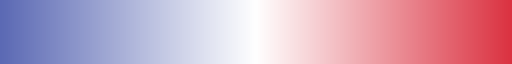

In [3]:
import matplotlib.colors as clr

cs = ["#5B69B4","#FFFFFF","#DB3241"]
red_blue = clr.LinearSegmentedColormap.from_list("cmap_name", cs)
red_blue 

In [4]:
palette_2={"WT":"powderblue",
 "KI":'orange'}
sns.color_palette(palette_2.values())

[(0.6901960784313725, 0.8784313725490196, 0.9019607843137255),
 (1.0, 0.6470588235294118, 0.0)]

In [5]:
palette_mut={"RNF212_KO":"#4A4063",
 "SIX6_D_Cterm":'#CD5334'}
sns.color_palette(palette_mut.values())

[(0.2901960784313726, 0.25098039215686274, 0.38823529411764707),
 (0.803921568627451, 0.3254901960784314, 0.20392156862745098)]

In [6]:
from sklearn.datasets import make_blobs
import colorcet as cc

blobs, labels = make_blobs(n_samples=1000, centers=25, center_box=(-100, 100))
cluster_colors = sns.color_palette(cc.glasbey_light, n_colors=25,as_cmap=True)
distinctipy = ['#4d51f9', '#4af85e', '#f1634e', '#5ad8fd', '#567562', '#ffe94c', '#ee74fc', '#b1ac99', '#a649bc', '#4e97bd', '#b0ff94', '#9f9afd', '#fbc0c7', '#94c64b', '#a14c4e']

If you want to save the images and tables in your computer change the path below

In [7]:
save_dir='/sas/sara/scRNAseq/pendas/'
adata = sc.read_h5ad(save_dir+"adata_reannotated4.h5ad")

In [8]:
adata.obs

,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,leiden_2_1.6,manually_annotation,leiden_S_0.1,leiden_S_0.2,leiden_S_0.4,leiden_S_0.6,leiden_S_0.8,leiden_S_1,leiden_S_1.2,leiden_S_1.4
ACACGCGCATAGAGGC-1-0-0,SI-TT-A1,SIX6_D_Cterm,7075.0,88695.0,7064.0,88695,1746.0,1.968544,6467.0,7.291279,...,17,MI,10,10,10,10,10,10,10,10
TGGGAGACAGTTGGTT-1-0-0,SI-TT-A1,SIX6_D_Cterm,6812.0,70090.0,6807.0,70090,1430.0,2.040234,5066.0,7.227850,...,17,MI,10,10,10,10,10,10,10,10
CACACAACATGGAGAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6892.0,68932.0,6885.0,68932,2420.0,3.510706,6916.0,10.033076,...,14,lP2,4,4,4,4,4,4,4,4
GAAATGAAGCCTCCAG-1-0-0,SI-TT-A1,SIX6_D_Cterm,6416.0,58599.0,6410.0,58599,1323.0,2.257718,4214.0,7.191249,...,17,D,10,10,10,10,10,10,10,10
TGATTCTAGCCTCTTC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6418.0,57103.0,6407.0,57103,1152.0,2.017407,4287.0,7.507486,...,17,D,10,10,10,10,10,10,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ACATTTCTCGCCAGTG-1-4-0,SI-TT-H12,RNF212_KO,208.0,323.0,208.0,323,15.0,4.643963,159.0,49.226006,...,4,Spermatogonia,8,8,8,8,8,8,8,8
GAAACCTCACCTGCAG-1-4-0,SI-TT-H12,RNF212_KO,288.0,373.0,288.0,373,8.0,2.144772,106.0,28.418231,...,4,Spermatogonia,8,8,8,8,8,8,8,8
AAGTCGTAGGTGTGAC-1-4-0,SI-TT-H12,RNF212_KO,226.0,324.0,226.0,324,8.0,2.469136,90.0,27.777778,...,12,Fibroblasts,14,14,14,14,14,14,14,14
AGTAGTCTCTGGTCAA-1-4-0,SI-TT-H12,RNF212_KO,221.0,328.0,221.0,328,7.0,2.134146,152.0,46.341463,...,4,Spermatogonia,8,8,8,8,8,8,8,8


In [9]:
### Analysis subpopulations
temp = pd.DataFrame(adata.obs["Group"])
temp["barcodes"] = list(adata.obs.index)
count=temp.groupby(["Group"]).count()
count["Group"]= count.index
count

,barcodes,Group
Group,,
H2AX_KI,9981,H2AX_KI
RNF212_KO,4511,RNF212_KO
SIX6_D_Cterm,8666,SIX6_D_Cterm
WT1,1381,WT1
WT2,3119,WT2


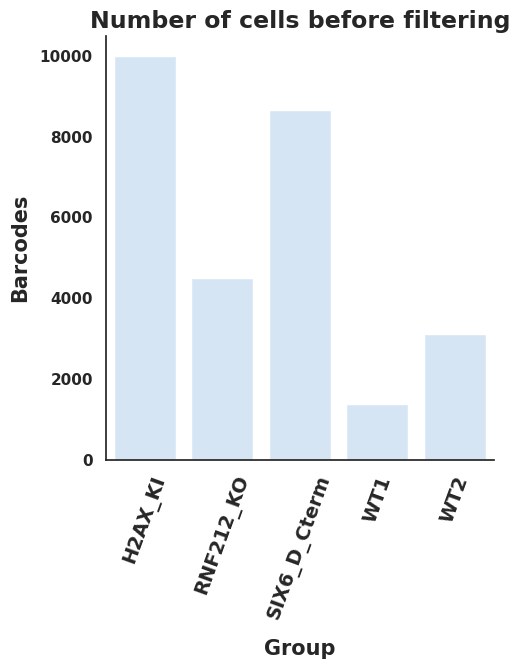

In [10]:
sns.set_theme(style="white")
plt.rcParams.update({"axes.labelpad":40,"axes.labelweight":"bold","axes.titleweight":"bold",'font.size': 13, "font.weight":"bold"})

plt.figure(figsize=[5, 5.5])
sns.barplot(data=count, x="Group", y="barcodes",color="#D1E5F8")
plt.xticks(rotation=70,size=14)
plt.ylabel("Barcodes",labelpad=7,size=15)
plt.xlabel("Group",labelpad=12,size=15)
plt.title("Number of cells before filtering",weight="bold",size=17)
sns.despine()



In [11]:
adata.obs["Group"].unique()

['SIX6_D_Cterm', 'WT2', 'WT1', 'H2AX_KI', 'RNF212_KO']
Categories (5, object): ['H2AX_KI', 'RNF212_KO', 'SIX6_D_Cterm', 'WT1', 'WT2']

Change the list below to define the populations and samples that you want to use in the comparison

In [12]:
labels=["eP2"]
groups=["WT1","WT2","H2AX_KI"]

In [13]:
subset = adata[(adata.obs["manually_annotation"].isin(labels)) & (adata.obs["Group"].isin(groups))]
subset

View of AnnData object with n_obs × n_vars = 295 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_

You need to balance the number of cell per condition of sample to avoid that one outlier take too much protagonism

In [14]:
np.random.seed(42)

samples = subset.obs['Sample'].unique() 

selected_cells = []

for sample in samples:
    sample_cells = subset.obs[subset.obs['Sample'] == sample].index  # Obtén las células de este sample
    if len(sample_cells) > 100:
        # Selecciona 1000 células de forma aleatoria
        selected = np.random.choice(sample_cells, size=100, replace=False)
    else:
        # Si hay menos de 1000 células, selecciona todas
        selected = sample_cells
    selected_cells.extend(selected)

# Crea un nuevo AnnData con las células seleccionadas
adata_subset = subset[selected_cells].copy()

# Mezcla las células seleccionadas de forma aleatoria
adata_subset = adata_subset[np.random.permutation(adata_subset.n_obs)].copy()
adata_subset

AnnData object with n_obs × n_vars = 221 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1', 'lei

In [15]:
sc.tl.rank_genes_groups(adata_subset, groupby="Condition",layer="normalized_expression_log")

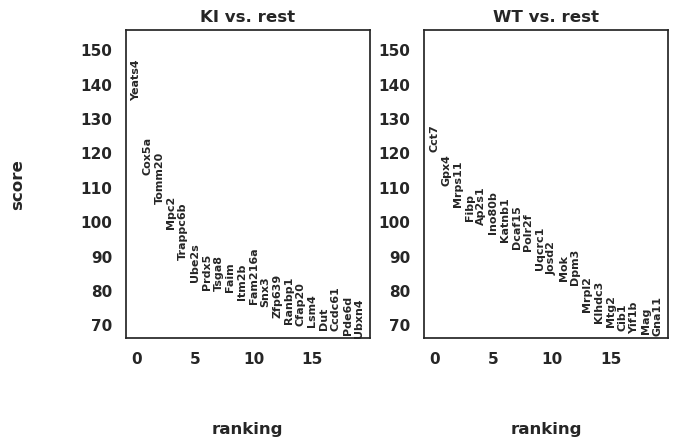

In [16]:
sc.pl.rank_genes_groups(adata_subset)

In [17]:
labels

['eP2']

In [18]:
de_df = sc.get.rank_genes_groups_df(adata_subset, group="KI")
de_df.to_csv(save_dir+"/tables/de_genes_"+'_'.join(labels)+"_"+"_".join(groups)+".csv")
de_df

,names,scores,logfoldchanges,pvals,pvals_adj
0,Yeats4,135.159637,2.369942,1.660902e-167,2.638343e-164
1,Cox5a,113.714447,3.664283,1.450653e-114,1.772586e-112
2,Tomm20,105.153397,2.722853,1.153445e-127,2.893021e-125
3,Mpc2,97.958145,2.510239,4.480416e-172,1.067571e-168
4,Trappc6b,89.067482,2.030474,4.327181e-146,2.577648e-143
...,...,...,...,...,...
9526,Ap2s1,-99.271530,-2.318628,3.687101e-169,7.028353e-166
9527,Fibp,-100.406662,-2.023366,1.326968e-183,6.323664e-180
9528,Mrps11,-104.403893,-2.394124,1.642088e-181,5.216915e-178
9529,Gpx4,-110.391167,-4.004086,9.362633e-166,1.274789e-162


In [19]:
de_df.head(30)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Yeats4,135.159637,2.369942,1.660902e-167,2.638343e-164
1,Cox5a,113.714447,3.664283,1.450653e-114,1.772586e-112
2,Tomm20,105.153397,2.722853,1.153445e-127,2.893021e-125
3,Mpc2,97.958145,2.510239,4.480416e-172,1.067571e-168
4,Trappc6b,89.067482,2.030474,4.327181e-146,2.577648e-143
5,Ube2s,82.499413,2.041614,2.325444e-154,2.216381e-151
6,Prdx5,80.153435,1.986769,1.850254e-131,5.343871e-129
7,Tsga8,79.966301,4.686762,2.065638e-96,1.036189e-94
8,Faim,79.817093,1.501968,3.240171e-147,2.205862e-144
9,Itm2b,77.409698,1.906141,7.129417e-121,1.213401e-118


In [20]:
top = de_df.sort_values(by="scores").head(100)
tail = de_df.sort_values(by="scores").tail(100)

de_top = pd.concat([top, tail], ignore_index=True)
de_top

,names,scores,logfoldchanges,pvals,pvals_adj
0,Cct7,-120.473999,-2.178863,5.471837e-202,5.215208e-198
1,Gpx4,-110.391167,-4.004086,9.362633e-166,1.274789e-162
2,Mrps11,-104.403893,-2.394124,1.642088e-181,5.216915e-178
3,Fibp,-100.406662,-2.023366,1.326968e-183,6.323664e-180
4,Ap2s1,-99.271530,-2.318628,3.687101e-169,7.028353e-166
...,...,...,...,...,...
195,Trappc6b,89.067482,2.030474,4.327181e-146,2.577648e-143
196,Mpc2,97.958145,2.510239,4.480416e-172,1.067571e-168
197,Tomm20,105.153397,2.722853,1.153445e-127,2.893021e-125
198,Cox5a,113.714447,3.664283,1.450653e-114,1.772586e-112


If you want to check the expression of a specific gene change the label below

In [21]:
gene="Grap"

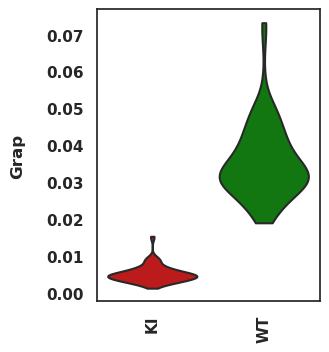

In [22]:
plt.rcParams.update({"axes.labelpad":15})

sc.pl.violin(adata_subset, groupby="Condition",keys=gene, rotation=90, multi_panel=True, stripplot=False,return_fig=True)


## GSEA

In [23]:
import gseapy as gp
names = gp.get_library_name()
print(names)

['ARCHS4_Cell-lines', 'ARCHS4_IDG_Coexp', 'ARCHS4_Kinases_Coexp', 'ARCHS4_TFs_Coexp', 'ARCHS4_Tissues', 'Achilles_fitness_decrease', 'Achilles_fitness_increase', 'Aging_Perturbations_from_GEO_down', 'Aging_Perturbations_from_GEO_up', 'Allen_Brain_Atlas_10x_scRNA_2021', 'Allen_Brain_Atlas_down', 'Allen_Brain_Atlas_up', 'Azimuth_2023', 'Azimuth_Cell_Types_2021', 'BioCarta_2013', 'BioCarta_2015', 'BioCarta_2016', 'BioPlanet_2019', 'BioPlex_2017', 'CCLE_Proteomics_2020', 'CM4AI_U2OS_Protein_Localization_Assemblies', 'COMPARTMENTS_Curated_2025', 'COMPARTMENTS_Experimental_2025', 'CORUM', 'COVID-19_Related_Gene_Sets', 'COVID-19_Related_Gene_Sets_2021', 'Cancer_Cell_Line_Encyclopedia', 'CellMarker_2024', 'CellMarker_Augmented_2021', 'ChEA_2013', 'ChEA_2015', 'ChEA_2016', 'ChEA_2022', 'Chromosome_Location', 'Chromosome_Location_hg19', 'ClinVar_2019', 'ClinVar_2025', 'DGIdb_Drug_Targets_2024', 'DSigDB', 'Data_Acquisition_Method_Most_Popular_Genes', 'DepMap_CRISPR_GeneDependency_CellLines_2023',

In [24]:
rnk = pd.DataFrame(de_top["scores"].to_list(), index =de_top["names"].to_list())
rnk

,0
Cct7,-120.473999
Gpx4,-110.391167
Mrps11,-104.403893
Fibp,-100.406662
Ap2s1,-99.271530
...,...
Trappc6b,89.067482
Mpc2,97.958145
Tomm20,105.153397
Cox5a,113.714447


In [25]:
rnk[50:100]

,0
Pold1,-55.710705
Map3k11,-55.443256
Ube2m,-55.040325
Git1,-54.764271
Pnkd,-53.705372
Stk11,-53.693298
Rabl6,-53.387501
Ccdc151,-53.133640
Clmp,-52.722290
Tom1l2,-52.014774


In [26]:
enr = gp.enrichr(gene_list=list(de_top["names"]), # or "./tests/data/gene_list.txt",
                 gene_sets=['KEGG_2019_Mouse'],
                 organism='mouse', # don't forget to set organism to the one you desired! e.g. Yeast
                 outdir=None, # don't write to disk
                )
enr.results["n_genes"] = enr.results["Overlap"].str.split("/",expand=True)[0].astype(int)
enr.results["% genes"] = enr.results["n_genes"] / enr.results["Overlap"].str.split("/",expand=True)[1].astype(int)

enr.results[(enr.results["n_genes"]>4)  ].sort_values(by="Combined Score",ascending=False).head(25)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,n_genes,% genes
0,KEGG_2019_Mouse,Autophagy,7/130,0.000337,0.041815,0,0,5.802224,46.388736,STK11;NRAS;MAP2K2;RHEB;PIK3R2;TRP53INP2;MAPK3,7,0.053846
3,KEGG_2019_Mouse,Fc gamma R-mediated phagocytosis,5/87,0.001810,0.041815,0,0,6.165729,38.932202,CFL2;PIK3R2;ARPC4;DNM2;MAPK3,5,0.057471
2,KEGG_2019_Mouse,mTOR signaling pathway,7/154,0.000927,0.041815,0,0,4.849001,33.864049,STK11;NRAS;MAP2K2;RHEB;PIK3R2;WDR24;MAPK3,7,0.045455
1,KEGG_2019_Mouse,Huntington disease,8/192,0.000717,0.041815,0,0,4.442029,32.164683,NDUFB11;UQCRC1;AP2S1;CLTA;POLR2F;POLR2I;SOD2;C...,8,0.041667
11,KEGG_2019_Mouse,Choline metabolism in cancer,5/99,0.003183,0.041815,0,0,5.375341,30.907872,NRAS;MAP2K2;RHEB;PIK3R2;MAPK3,5,0.050505
4,KEGG_2019_Mouse,FoxO signaling pathway,6/132,0.002141,0.041815,0,0,4.829161,29.682124,STK11;NRAS;MAP2K2;PIK3R2;SOD2;MAPK3,6,0.045455
14,KEGG_2019_Mouse,Longevity regulating pathway,5/102,0.003619,0.041815,0,0,5.208300,29.278945,STK11;NRAS;RHEB;PIK3R2;SOD2,5,0.049020
5,KEGG_2019_Mouse,Ubiquitin mediated proteolysis,6/138,0.002675,0.041815,0,0,4.608247,27.298200,CDC20;UBE2W;UBE2S;UBE2D3;CDC16;UBE2M,6,0.043478
9,KEGG_2019_Mouse,Insulin signaling pathway,6/139,0.002773,0.041815,0,0,4.573366,26.927194,NRAS;MAP2K2;RHEB;INPP5K;PIK3R2;MAPK3,6,0.043165
16,KEGG_2019_Mouse,Phospholipase D signaling pathway,6/149,0.003906,0.041815,0,0,4.251388,23.575231,NRAS;MAP2K2;RHEB;PIK3R2;DNM2;MAPK3,6,0.040268


In [27]:
enr = gp.enrichr(gene_list=list(de_top["names"]), # or "./tests/data/gene_list.txt",
                 gene_sets=['GO_Biological_Process_2023'],
                 organism='mouse', # don't forget to set organism to the one you desired! e.g. Yeast
                 outdir=None, # don't write to disk
                )
enr.results["n_genes"] = enr.results["Overlap"].str.split("/",expand=True)[0].astype(int)
enr.results["% genes"] = enr.results["n_genes"] / enr.results["Overlap"].str.split("/",expand=True)[1].astype(int)

enr.results[(enr.results["n_genes"]>4)  ].sort_values(by="Combined Score",ascending=False).head(25)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,n_genes,% genes
1,GO_Biological_Process_2023,Macromolecule Modification (GO:0043412),6/81,0.000161,0.072879,0,0,8.134021,71.019971,PRMT6;SERP1;UBE2S;MCRS1;UBE2D3;UBE2M,6,0.074074
0,GO_Biological_Process_2023,Protein Targeting (GO:0006605),8/129,0.000047,0.054404,0,0,6.776515,67.509731,PEX16;HPS4;KATNB1;AP4S1;MFF;TOMM20;ZDHHC4;YIF1B,8,0.062016
14,GO_Biological_Process_2023,MAPK Cascade (GO:0000165),5/98,0.003046,0.197074,0,0,5.433416,31.479928,NRAS;MAP2K2;PABPN1;MAP3K11;MAPK3,5,0.051020
15,GO_Biological_Process_2023,Regulation Of Organelle Organization (GO:0033043),5/100,0.003324,0.197074,0,0,5.318489,30.350700,PRMT6;INO80B;MCRS1;MFF;MAPK3,5,0.050000
6,GO_Biological_Process_2023,Proteasome-Mediated Ubiquitin-Dependent Protei...,10/319,0.001446,0.197074,0,0,3.319877,21.707432,CDC20;ATXN3;KLHDC3;UBE2W;UBXN11;UBE2S;CDC16;UB...,10,0.031348
41,GO_Biological_Process_2023,Receptor-Mediated Endocytosis (GO:0006898),5/122,0.007679,0.210988,0,0,4.313609,21.004147,RNASEK;AP2S1;AP1S1;CLTA;DNM2,5,0.040984
31,GO_Biological_Process_2023,Mitochondrion Organization (GO:0007005),6/162,0.005851,0.197074,0,0,3.894528,20.022413,CHCHD4;CHCHD2;MTX2;MFF;PHB2;TOMM20,6,0.037037
43,GO_Biological_Process_2023,Positive Regulation Of Intracellular Protein T...,5/126,0.008764,0.227372,0,0,4.170163,19.754463,UBE2D3;HPS4;CIB1;PIK3R2;MFF,5,0.039683
44,GO_Biological_Process_2023,DNA Repair (GO:0006281),8/291,0.009137,0.227372,0,0,2.873528,13.492338,PRMT6;ATXN3;ENDOV;ASCC1;POLD1;NUCKS1;CIB1;POLL,8,0.027491
62,GO_Biological_Process_2023,Golgi Vesicle Transport (GO:0048193),6/197,0.014481,0.262052,0,0,3.175204,13.446623,SNX3;ARF4;TRAPPC6B;TRAPPC5;YIF1B;DNM2,6,0.030457


In [28]:
for x in enr.results[(enr.results["n_genes"]>4)  ].sort_values(by="Combined Score",ascending=False).head(7)["Term"]:
    print(x)

Macromolecule Modification (GO:0043412)
Protein Targeting (GO:0006605)
MAPK Cascade (GO:0000165)
Regulation Of Organelle Organization (GO:0033043)
Proteasome-Mediated Ubiquitin-Dependent Protein Catabolic Process (GO:0043161)
Receptor-Mediated Endocytosis (GO:0006898)
Mitochondrion Organization (GO:0007005)


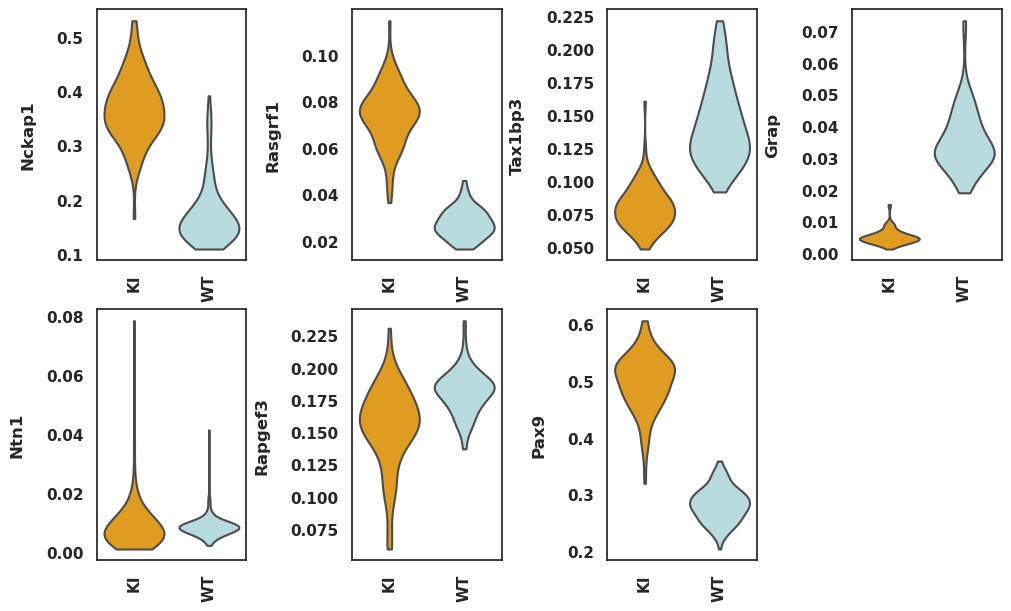

In [29]:
genes = ["Nckap1", "Rasgrf1","Tax1bp3","Grap","Ntn1","Rapgef3","Pax9"]

# Create figure and axes
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(10, 6),              # adjust height since 2 rows
    constrained_layout=True
)

# Flatten axes array for easy iteration
axes = axes.flatten()

for ax, gene in zip(axes, genes):
    sc.pl.violin(
        adata_subset,
        keys=[gene],
        groupby='Condition',
        palette=palette_2,
        jitter=0.4,
        rotation=90,
        stripplot=False,
        multi_panel=False,
        show=False,
        ax=ax
    )

# Hide any unused axes (since you have 8 axes but only 7 genes)
for ax in axes[len(genes):]:
    ax.set_visible(False)

plt.show()


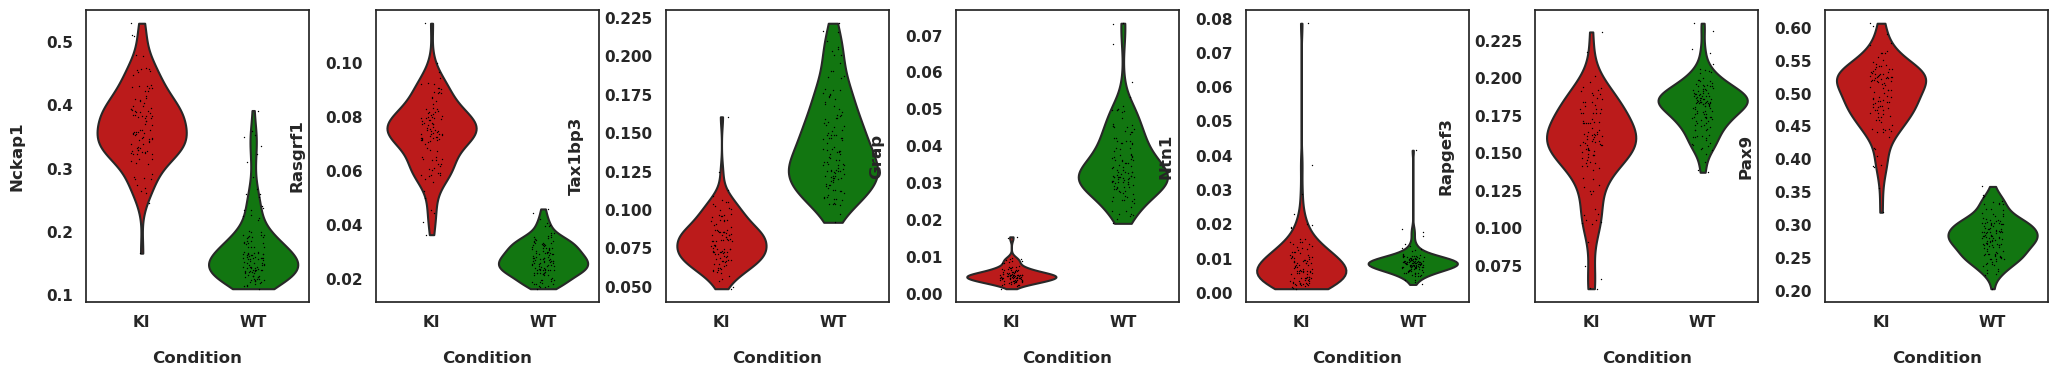

In [30]:
sc.pl.violin(adata_subset, groupby="Condition",keys=["Nckap1", "Rasgrf1","Tax1bp3","Grap","Ntn1","Rapgef3","Pax9"])

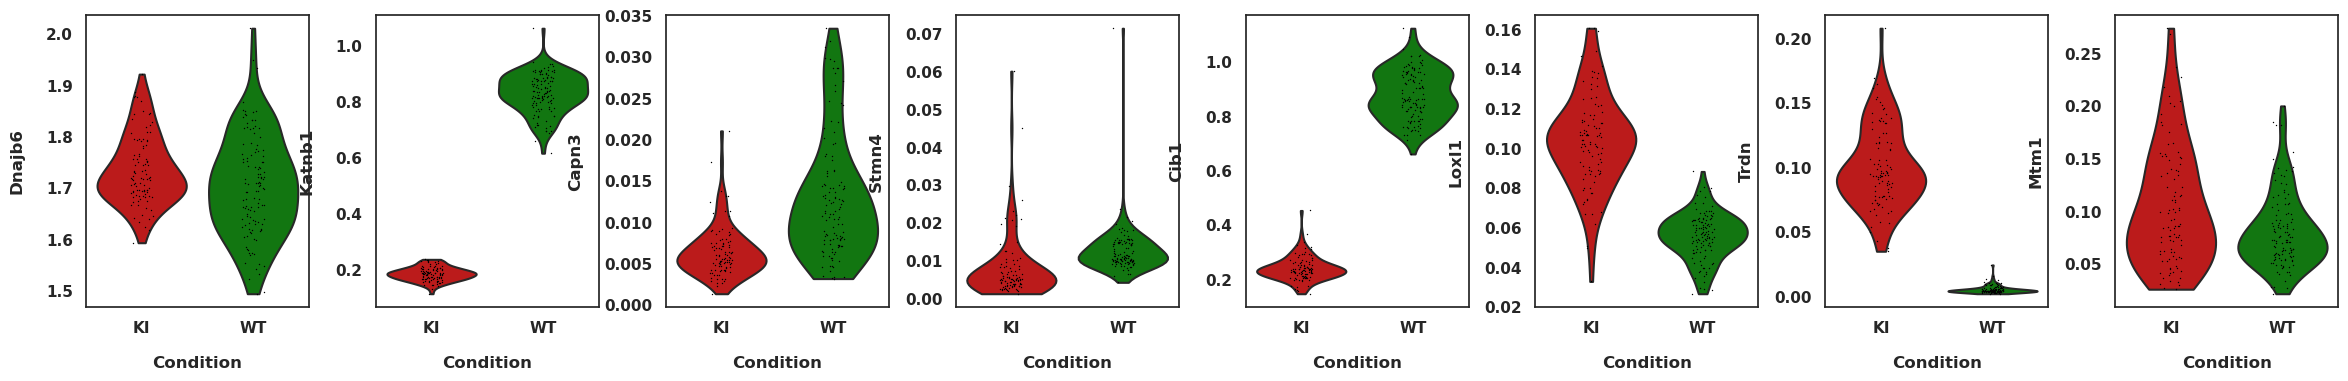

In [31]:
sc.pl.violin(adata_subset, groupby="Condition",keys=["Dnajb6","Katnb1","Capn3","Stmn4","Cib1","Loxl1","Trdn","Mtm1"])

In [32]:
adata_subset.layers

Layers with keys: counts, normalized_expression, normalized_expression_log

In [33]:
data_expr = pd.DataFrame(adata_subset.layers["normalized_expression_log"])

data_expr.columns = adata_subset.var_names
data_expr.index = adata_subset.obs_names
data_expr.head(5)

,Rp1,Sox17,Tcea1,Atp6v1h,Rb1cc1,Pcmtd1,Sntg1,Rrs1,Adhfe1,Mybl1,...,mt-Co3,mt-Nd3,mt-Nd4l,mt-Nd4,mt-Nd5,mt-Nd6,mt-Cytb,AC168977.1,AC132444.6,Vamp7
AACCATGTCATCTACT-1-1-0,0.426120,0.010095,0.858471,1.166631,2.428951,0.035222,0.007529,0.381576,0.004639,0.983113,...,4.623446,1.835458,1.294218,3.334553,1.802871,0.284164,3.779269,0.001760,0.004663,0.049479
CATCCACAGTCTAGCT-1-3-0,0.350158,0.006927,1.516434,1.183675,1.919782,0.051886,0.006535,0.275880,0.005714,1.265355,...,4.347950,1.892294,1.599060,3.684350,2.193759,0.332053,4.135645,0.003090,0.014025,0.168940
TCTACCGGTGACAGGT-1-2-0,0.366244,0.014028,0.606988,1.153749,2.394159,0.045204,0.017688,0.344531,0.005224,0.869351,...,5.057099,2.497177,1.108973,3.746537,1.910637,0.314476,4.187177,0.004356,0.010340,0.036818
TCCTGCAAGGAGACCT-1-1-0,0.401349,0.008647,0.717918,1.111338,2.417328,0.036500,0.008359,0.428726,0.004582,0.844623,...,4.814786,1.942473,1.333413,3.470433,1.821563,0.223743,3.921850,0.001796,0.005274,0.052618
CCGGACAGTCATCAGT-1-3-0,0.450661,0.008054,1.428727,1.130741,1.904912,0.062668,0.006548,0.298728,0.011146,1.306499,...,4.553814,2.139715,1.703700,3.885426,2.342828,0.240840,4.306543,0.003458,0.015312,0.214908


In [34]:
adata_subset.obs

,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,leiden_2_1.6,manually_annotation,leiden_S_0.1,leiden_S_0.2,leiden_S_0.4,leiden_S_0.6,leiden_S_0.8,leiden_S_1,leiden_S_1.2,leiden_S_1.4
AACCATGTCATCTACT-1-1-0,SI-TT-B1,WT2,4877.0,22518.0,4873.0,22518,703.0,3.121947,2291.0,10.174083,...,9,eP2,11,11,11,11,11,11,11,11
CATCCACAGTCTAGCT-1-3-0,SI-TT-D1,H2AX_KI,3777.0,13457.0,3774.0,13457,459.0,3.410864,1280.0,9.511778,...,6,eP2,11,11,11,11,11,11,11,11
TCTACCGGTGACAGGT-1-2-0,SI-TT-C1,WT1,5899.0,33501.0,5891.0,33501,1484.0,4.429719,3088.0,9.217635,...,9,eP2,11,11,11,11,11,11,11,11
TCCTGCAAGGAGACCT-1-1-0,SI-TT-B1,WT2,4128.0,15157.0,4125.0,15157,615.0,4.057531,1743.0,11.499637,...,9,eP2,11,11,11,11,11,11,11,11
CCGGACAGTCATCAGT-1-3-0,SI-TT-D1,H2AX_KI,2676.0,6772.0,2674.0,6772,259.0,3.824572,603.0,8.904312,...,9,eP2,11,11,11,11,11,11,11,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CCACACTCAATGACCT-1-1-0,SI-TT-B1,WT2,5769.0,31758.0,5759.0,31758,639.0,2.012091,3407.0,10.728006,...,9,eP2,11,11,11,11,11,11,11,11
TCATCCGTCAACCCGG-1-3-0,SI-TT-D1,H2AX_KI,2149.0,4654.0,2147.0,4654,96.0,2.062742,500.0,10.743446,...,6,eP2,6,6,6,6,6,6,6,6
GATGAGGTCTCTTGCG-1-2-0,SI-TT-C1,WT1,4241.0,14948.0,4239.0,14948,1267.0,8.476050,1305.0,8.730265,...,6,eP2,6,6,6,6,6,6,6,6
ACTTTCAAGTTCGGTT-1-2-0,SI-TT-C1,WT1,3291.0,10388.0,3291.0,10388,753.0,7.248749,1158.0,11.147478,...,6,eP2,6,6,6,6,6,6,6,6


In [35]:
data_expr[["Group","Sample","Condition"]] = adata_subset.obs[["Group","Sample","Condition"]]
data_expr

,Rp1,Sox17,Tcea1,Atp6v1h,Rb1cc1,Pcmtd1,Sntg1,Rrs1,Adhfe1,Mybl1,...,mt-Nd4,mt-Nd5,mt-Nd6,mt-Cytb,AC168977.1,AC132444.6,Vamp7,Group,Sample,Condition
AACCATGTCATCTACT-1-1-0,0.426120,0.010095,0.858471,1.166631,2.428951,0.035222,0.007529,0.381576,0.004639,0.983113,...,3.334553,1.802871,0.284164,3.779269,0.001760,0.004663,0.049479,WT2,SI-TT-B1,WT
CATCCACAGTCTAGCT-1-3-0,0.350158,0.006927,1.516434,1.183675,1.919782,0.051886,0.006535,0.275880,0.005714,1.265355,...,3.684350,2.193759,0.332053,4.135645,0.003090,0.014025,0.168940,H2AX_KI,SI-TT-D1,KI
TCTACCGGTGACAGGT-1-2-0,0.366244,0.014028,0.606988,1.153749,2.394159,0.045204,0.017688,0.344531,0.005224,0.869351,...,3.746537,1.910637,0.314476,4.187177,0.004356,0.010340,0.036818,WT1,SI-TT-C1,WT
TCCTGCAAGGAGACCT-1-1-0,0.401349,0.008647,0.717918,1.111338,2.417328,0.036500,0.008359,0.428726,0.004582,0.844623,...,3.470433,1.821563,0.223743,3.921850,0.001796,0.005274,0.052618,WT2,SI-TT-B1,WT
CCGGACAGTCATCAGT-1-3-0,0.450661,0.008054,1.428727,1.130741,1.904912,0.062668,0.006548,0.298728,0.011146,1.306499,...,3.885426,2.342828,0.240840,4.306543,0.003458,0.015312,0.214908,H2AX_KI,SI-TT-D1,KI
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CCACACTCAATGACCT-1-1-0,0.380951,0.009202,1.039587,1.208582,2.242249,0.034514,0.007095,0.353163,0.004037,0.895429,...,3.138723,1.610907,0.174669,3.678705,0.001393,0.002984,0.055123,WT2,SI-TT-B1,WT
TCATCCGTCAACCCGG-1-3-0,0.391201,0.005472,1.530437,1.265013,1.759454,0.027696,0.004898,0.282533,0.003905,1.089242,...,3.183894,1.686922,0.110726,3.712805,0.002751,0.013076,0.177980,H2AX_KI,SI-TT-D1,KI
GATGAGGTCTCTTGCG-1-2-0,0.173644,0.020241,1.097925,1.186943,2.215039,0.120912,0.013862,0.297382,0.005620,1.150682,...,4.311948,2.458126,0.460722,4.806116,0.003816,0.009573,0.088888,WT1,SI-TT-C1,WT
ACTTTCAAGTTCGGTT-1-2-0,0.180820,0.017978,1.018264,1.190271,2.104814,0.062415,0.013177,0.287804,0.003878,0.908471,...,3.987086,1.998530,0.222295,4.580153,0.003840,0.005998,0.060767,WT1,SI-TT-C1,WT


In [36]:
gene="Cib1"


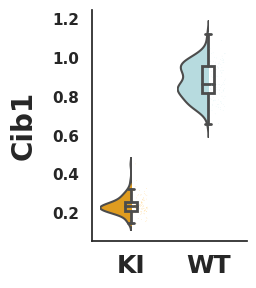

In [37]:
#plt.rcParams['figure.figsize'] =2,3

plt.figure(figsize=(2, 3))

ax = sns.violinplot(x="Condition",y=gene, data=data_expr, hue="Condition", dodge=False,
                    palette=palette_2,
                    scale="width", inner=None)
xlim = ax.get_xlim()
ylim = ax.get_ylim()
for violin in ax.collections:
    bbox = violin.get_paths()[0].get_extents()
    x0, y0, width, height = bbox.bounds
    violin.set_clip_path(plt.Rectangle((x0, y0), width / 2, height, transform=ax.transData))


old_len_collections = len(ax.collections)
sns.stripplot(x="Condition",y=gene, data=data_expr, hue="Condition", palette=palette_2, dodge=False, ax=ax,s=0.3)
for dots in ax.collections[old_len_collections:]:
    dots.set_offsets(dots.get_offsets() + np.array([0.12, 0]))
sns.boxplot(x="Condition",y=gene, data=data_expr, saturation=1, showfliers=False,
            width=0.15, boxprops={'zorder': 3, 'facecolor': 'none'}, ax=ax,linewidth=2)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.xlabel("")
plt.xticks(weight="bold",size=18)
plt.ylabel(gene,weight="bold",size=20,labelpad=10)
sns.despine()
plt.gca().get_legend().remove()

#ax.legend_.remove()
plt.show()

In [38]:
enr = gp.enrichr(gene_list=list(de_top["names"]), # or "./tests/data/gene_list.txt",
                 gene_sets=['GO_Molecular_Function_2023'],
                 organism='mouse', # don't forget to set organism to the one you desired! e.g. Yeast
                 outdir=None, # don't write to disk
                )
enr.results["n_genes"] = enr.results["Overlap"].str.split("/",expand=True)[0].astype(int)
enr.results["% genes"] = enr.results["n_genes"] / enr.results["Overlap"].str.split("/",expand=True)[1].astype(int)

enr.results[(enr.results["n_genes"]>4)  ].sort_values(by="Combined Score",ascending=False).head(25)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,n_genes,% genes
3,GO_Molecular_Function_2023,GTP Binding (GO:0005525),7/201,0.004179,0.192751,0,0,3.665456,20.077893,ARF4;NRAS;RAB14;MTG2;GNA11;RABL6;DNM2,7,0.034826
7,GO_Molecular_Function_2023,Guanyl Ribonucleotide Binding (GO:0032561),7/226,0.007812,0.192751,0,0,3.242885,15.734869,ARF4;NRAS;RAB14;MTG2;GNA11;RABL6;DNM2,7,0.030973
15,GO_Molecular_Function_2023,Ubiquitin-Like Protein Transferase Activity (G...,6/240,0.033956,0.300556,0,0,2.586043,8.747785,RNF123;UBE2W;UBE2S;UBE2D3;RNF6;UBE2M,6,0.025000
18,GO_Molecular_Function_2023,Protein Heterodimerization Activity (GO:0046982),5/190,0.042418,0.300556,0,0,2.718642,8.591435,TCOF1;KATNB1;PIK3R2;PHB2;PAFAH1B1,5,0.026316
28,GO_Molecular_Function_2023,Small GTPase Binding (GO:0031267),5/199,0.049960,0.300556,0,0,2.591330,7.764991,RANBP1;HPS4;PDE6D;CIB1;GIT1,5,0.025126
30,GO_Molecular_Function_2023,GTPase Activity (GO:0003924),6/265,0.050693,0.300556,0,0,2.333439,6.958237,ARF4;NRAS;RAB14;MTG2;GNA11;DNM2,6,0.022642
31,GO_Molecular_Function_2023,Ribonucleoside Triphosphate Phosphatase Activi...,6/270,0.054554,0.300556,0,0,2.288660,6.656726,ARF4;NRAS;RAB14;MTG2;GNA11;DNM2,6,0.022222
47,GO_Molecular_Function_2023,GTPase Binding (GO:0051020),5/225,0.075907,0.300556,0,0,2.282051,5.883699,RANBP1;HPS4;PDE6D;CIB1;GIT1,5,0.022222
61,GO_Molecular_Function_2023,Microtubule Binding (GO:0008017),5/239,0.092397,0.300556,0,0,2.143984,5.106242,KATNB1;TPGS1;CCDC61;PAFAH1B1;DNM2,5,0.020921
19,GO_Molecular_Function_2023,RNA Binding (GO:0003723),21/1411,0.043987,0.300556,0,0,1.553836,4.853982,EIF5A;POP5;DUT;CHTOP;RPS19BP1;MCRS1;MRPS11;NUC...,21,0.014883


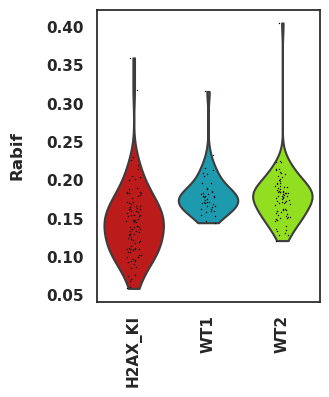

In [39]:
sc.pl.violin(adata_subset, groupby="Group",keys=["Rabif"],rotation=90)

In [40]:
top = de_df.sort_values(by="scores").head(25)
tail = de_df.sort_values(by="scores").tail(25)

de_top = pd.concat([top, tail], ignore_index=True)
de_top


,names,scores,logfoldchanges,pvals,pvals_adj
0,Cct7,-120.473999,-2.178863,5.471837e-202,5.215208e-198
1,Gpx4,-110.391167,-4.004086,9.362633e-166,1.274789e-162
2,Mrps11,-104.403893,-2.394124,1.642088e-181,5.216915e-178
3,Fibp,-100.406662,-2.023366,1.326968e-183,6.323664e-180
4,Ap2s1,-99.271530,-2.318628,3.687101e-169,7.028353e-166
5,Ino80b,-96.485909,-2.686697,1.214363e-130,3.404145e-128
6,Katnb1,-94.299217,-2.689222,7.217542e-138,3.126836e-135
7,Dcaf15,-92.269081,-2.823378,6.884441e-147,4.374374e-144
8,Polr2f,-91.661255,-3.323171,2.211291e-123,4.132512e-121
9,Uqcrc1,-85.993553,-3.090520,4.118768e-162,4.906997e-159


In [41]:
subset.X.shape

(295, 9531)

In [42]:
subset_reduced =  adata_subset[:, de_top["names"]]
subset_reduced


View of AnnData object with n_obs × n_vars = 221 × 50
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1'

In [43]:
matrix_de = pd.DataFrame(subset_reduced.X) 
matrix_de.columns = de_top["names"]
matrix_de

names,Cct7,Gpx4,Mrps11,Fibp,Ap2s1,Ino80b,Katnb1,Dcaf15,Polr2f,Uqcrc1,...,Itm2b,Faim,Tsga8,Prdx5,Ube2s,Trappc6b,Mpc2,Tomm20,Cox5a,Yeats4
0,2.568802,2.420547,0.913518,1.333157,1.218555,0.226382,0.861405,0.601398,1.417904,1.909343,...,0.646050,0.512776,0.215290,0.603946,1.710615,0.740436,1.397296,0.568203,0.736068,0.691914
1,1.266580,0.476383,0.252375,0.554018,0.335465,0.041074,0.154498,0.115630,0.301080,0.515709,...,1.405003,1.030198,1.704187,1.547539,3.061347,1.555844,2.734635,1.845223,2.643585,1.663629
2,2.551619,2.521899,0.927584,1.273203,1.151251,0.255448,0.908963,0.661036,1.387690,1.886918,...,0.693426,0.552934,0.209092,0.578093,1.799861,0.679007,1.170724,0.578676,0.765814,0.659514
3,2.611191,2.533168,0.950381,1.316308,1.214514,0.236776,0.894326,0.662252,1.374828,1.947675,...,0.649965,0.471770,0.161269,0.571964,1.667674,0.718318,1.355656,0.562485,0.702946,0.658348
4,1.215792,0.471555,0.250915,0.531111,0.370477,0.044062,0.185364,0.109868,0.310784,0.410938,...,1.460306,1.035929,1.989066,1.434761,3.037728,1.611351,2.699633,1.915451,2.601219,1.632274
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
216,2.671631,2.500100,0.954139,1.441991,1.262012,0.240804,0.811547,0.529718,1.540039,1.941026,...,0.612170,0.503123,0.244549,0.638408,1.694205,0.704611,1.399604,0.564528,0.708050,0.668154
217,1.361371,0.525626,0.269778,0.559255,0.432761,0.043215,0.185650,0.111522,0.341015,0.564017,...,1.417373,1.156332,1.845217,1.650303,3.097956,1.624303,2.853649,1.874695,2.788850,1.674286
218,2.320191,2.178433,0.890097,1.321250,1.052095,0.244204,0.743505,0.599325,1.703658,1.668287,...,0.642016,0.473627,0.252943,0.690542,2.045173,0.623068,1.164223,0.793300,0.768121,0.586377
219,2.548892,2.455911,0.993821,1.467215,1.231219,0.286225,0.805296,0.685474,1.790371,1.933876,...,0.605061,0.503661,0.182792,0.661593,1.945727,0.570208,1.181371,0.690588,0.771901,0.569489


In [44]:
matrix_de.columns

Index(['Cct7', 'Gpx4', 'Mrps11', 'Fibp', 'Ap2s1', 'Ino80b', 'Katnb1', 'Dcaf15',
       'Polr2f', 'Uqcrc1', 'Josd2', 'Mok', 'Dpm3', 'Mrpl2', 'Klhdc3', 'Mtg2',
       'Cib1', 'Yif1b', 'Mag', 'Gna11', 'Slc25a1', 'Rpl8', 'Sbf1', 'Trmu',
       'Abhd17a', 'Chchd2', 'Fam92a', 'Phb2', 'Malsu1', 'Serp1', 'Ubxn4',
       'Pde6d', 'Ccdc61', 'Dut', 'Lsm4', 'Cfap20', 'Ranbp1', 'Zfp639', 'Snx3',
       'Fam216a', 'Itm2b', 'Faim', 'Tsga8', 'Prdx5', 'Ube2s', 'Trappc6b',
       'Mpc2', 'Tomm20', 'Cox5a', 'Yeats4'],
      dtype='object', name='names')

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.


<Figure size 350x400 with 0 Axes>

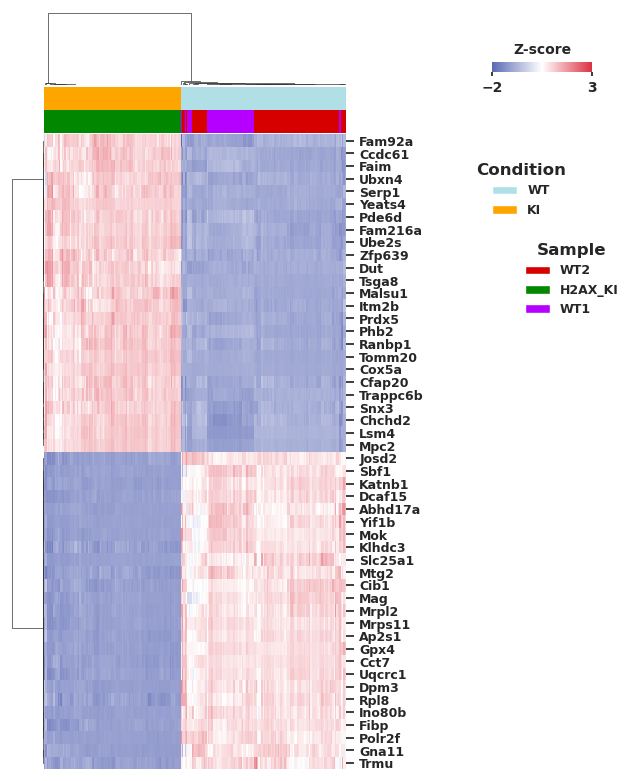

In [45]:
#subset.obs["Genotype_number"] = subset.obs["Genotype"].replace({ 'WT' : 0, 'KI' : 1 })
kws = dict(cbar_kws=dict(ticks=[-2,3],orientation='horizontal'), figsize=(5, 8))

fig = plt.figure()

sns.set(font_scale=1,context='notebook', style="white", palette=cluster_colors)


lut=palette_2
row_colors = pd.DataFrame(subset_reduced.obs["Condition"].to_list())[0].map(lut)


lut2 = dict(zip(set(subset_reduced.obs["Group"]), cluster_colors))
row_colors2 = pd.DataFrame(subset_reduced.obs["Group"].to_list())[0].map(lut2)


g=sns.clustermap(matrix_de.T, col_cluster=True,row_cluster=True,linewidths=0, cmap=red_blue, col_colors=[row_colors.to_numpy(),row_colors2.to_numpy()],yticklabels=True,xticklabels=False,method="average",metric="correlation",dendrogram_ratio = 0.1,**kws,vmax=3,vmin=-2,colors_ratio=0.03,z_score=0)
handles = [Patch(facecolor=lut[name]) for name in lut]
handles2 = [Patch(facecolor=lut2[name]) for name in lut2]

legend_group =plt.legend(handles, lut, title='Condition',bbox_to_anchor=(1.17, 0.8),fontsize=9,frameon=False,ncol=1,bbox_transform=plt.gcf().transFigure)

bbox_transform=plt.gcf().transFigure

legend_patient =plt.legend(handles2, lut2, title='Sample',bbox_to_anchor=(1.275, 0.7), bbox_transform=plt.gcf().transFigure,fontsize=9,frameon=False)

plt.setp(g.ax_heatmap.yaxis.get_majorticklabels(), size=9)

g.ax_heatmap.set_ylabel('')

g.ax_cbar.tick_params(axis='x', length=20,labelsize="small")

g.ax_cbar.set_position([1, 0.9, 0.2, 0.012])

g.ax_cbar.set_title('Z-score', size=10)

plt.gca().add_artist(legend_group)

cbar = g.cax

cbar.xaxis.set_tick_params(size=3)

plt.savefig(save_dir+"/figures/HeatmapDE_"+'_'.join(labels)+"_"+"_".join(groups)+".png",bbox_inches="tight",dpi=600,pad_inches=0.5)


plt.show()

In [46]:
sc.pp.filter_genes(adata_subset, min_counts=30)
adata_subset

AnnData object with n_obs × n_vars = 221 × 4569
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1', 'lei

In [47]:
res_BP = gp.gsea(data=pd.DataFrame(adata_subset.layers["normalized_expression_log"],columns=list(adata_subset.var_names.str.upper()),index=adata_subset.obs.index).T, # row -> genes, column-> samples
        gene_sets="GO_Biological_Process_2023",
        cls=adata_subset.obs.Condition,
        permutation_num=1000,
        min_size=50,
        permutation_type='phenotype',
        outdir=None,
        method='s2n', # signal_to_noise
        threads= 16)
res_BP

In [48]:
res_BP.res2d.head(30)


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,gsea,Mitochondrion Organization (GO:0007005),-0.451332,-1.622655,0.008081,1.0,0.286286,18/57,20.44%,TOMM20;PHB2;CHCHD2;MFF;MTX2;CHCHD4;GABPB1;BAX;...
1,gsea,Regulation Of Cellular Component Organization ...,0.437694,1.599538,0.016878,1.0,0.297,15/52,16.57%,AP2S1;STK11;MAD2L2;TRAF2;NCLN;HIP1R;RAPGEF1;PI...
2,gsea,Protein-Containing Complex Assembly (GO:0065003),0.313357,1.450153,0.046784,1.0,0.519,63/114,49.38%,GPX4;AP2S1;TRAPPC5;MAPK8IP2;TRAF2;PSMG3;TAPBP;...
3,gsea,Negative Regulation Of Apoptotic Process (GO:0...,-0.339347,-1.378064,0.068826,1.0,0.631632,57/121,32.96%,PRDX5;PHB2;PSMD10;FXN;SOD2;ARF4;SOD1;DNAJC3;VH...
4,gsea,Negative Regulation Of Programmed Cell Death (...,-0.320416,-1.357795,0.055336,1.0,0.660661,43/95,32.96%,PRDX5;PHB2;PSMD10;FXN;ARF4;DNAJC3;VHL;BNIP2;BA...
5,gsea,Golgi Vesicle Transport (GO:0048193),0.328344,1.343653,0.112205,1.0,0.656,47/92,47.21%,YIF1B;DNM2;TRAPPC5;STX18;WHAMM;TAPBP;YIF1A;SCF...
6,gsea,Positive Regulation Of Cellular Process (GO:00...,-0.302539,-1.342969,0.092929,1.0,0.682683,60/124,40.86%,CFAP20;PSMD10;FXN;DNAJA2;SS18;VHL;CD47;SRPK2;M...
7,gsea,Organelle Assembly (GO:0070925),0.369121,1.339561,0.131148,1.0,0.661,85/146,37.29%,HPS4;AP1S1;TEKT1;ATG7;WIPI2;CFAP70;HGS;ARL3;AP...
8,gsea,Cilium Assembly (GO:0060271),0.400862,1.269789,0.202454,1.0,0.75,80/120,37.29%,TEKT1;CCDC13;CFAP70;ARL3;CCDC40;RSPH9;FUZ;CEP8...
9,gsea,Protein Stabilization (GO:0050821),0.284863,1.260692,0.138277,1.0,0.758,36/83,41.08%,CCT7;HPS4;TBRG1;NCLN;BAG6;SYVN1;SPAG1;HIP1R;CO...


In [49]:
res_BP.res2d["gene_set"]= "GO_Biological_Process_2023"
res_BP.res2d.head(30)


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,gene_set
0,gsea,Mitochondrion Organization (GO:0007005),-0.451332,-1.622655,0.008081,1.0,0.286286,18/57,20.44%,TOMM20;PHB2;CHCHD2;MFF;MTX2;CHCHD4;GABPB1;BAX;...,GO_Biological_Process_2023
1,gsea,Regulation Of Cellular Component Organization ...,0.437694,1.599538,0.016878,1.0,0.297,15/52,16.57%,AP2S1;STK11;MAD2L2;TRAF2;NCLN;HIP1R;RAPGEF1;PI...,GO_Biological_Process_2023
2,gsea,Protein-Containing Complex Assembly (GO:0065003),0.313357,1.450153,0.046784,1.0,0.519,63/114,49.38%,GPX4;AP2S1;TRAPPC5;MAPK8IP2;TRAF2;PSMG3;TAPBP;...,GO_Biological_Process_2023
3,gsea,Negative Regulation Of Apoptotic Process (GO:0...,-0.339347,-1.378064,0.068826,1.0,0.631632,57/121,32.96%,PRDX5;PHB2;PSMD10;FXN;SOD2;ARF4;SOD1;DNAJC3;VH...,GO_Biological_Process_2023
4,gsea,Negative Regulation Of Programmed Cell Death (...,-0.320416,-1.357795,0.055336,1.0,0.660661,43/95,32.96%,PRDX5;PHB2;PSMD10;FXN;ARF4;DNAJC3;VHL;BNIP2;BA...,GO_Biological_Process_2023
5,gsea,Golgi Vesicle Transport (GO:0048193),0.328344,1.343653,0.112205,1.0,0.656,47/92,47.21%,YIF1B;DNM2;TRAPPC5;STX18;WHAMM;TAPBP;YIF1A;SCF...,GO_Biological_Process_2023
6,gsea,Positive Regulation Of Cellular Process (GO:00...,-0.302539,-1.342969,0.092929,1.0,0.682683,60/124,40.86%,CFAP20;PSMD10;FXN;DNAJA2;SS18;VHL;CD47;SRPK2;M...,GO_Biological_Process_2023
7,gsea,Organelle Assembly (GO:0070925),0.369121,1.339561,0.131148,1.0,0.661,85/146,37.29%,HPS4;AP1S1;TEKT1;ATG7;WIPI2;CFAP70;HGS;ARL3;AP...,GO_Biological_Process_2023
8,gsea,Cilium Assembly (GO:0060271),0.400862,1.269789,0.202454,1.0,0.75,80/120,37.29%,TEKT1;CCDC13;CFAP70;ARL3;CCDC40;RSPH9;FUZ;CEP8...,GO_Biological_Process_2023
9,gsea,Protein Stabilization (GO:0050821),0.284863,1.260692,0.138277,1.0,0.758,36/83,41.08%,CCT7;HPS4;TBRG1;NCLN;BAG6;SYVN1;SPAG1;HIP1R;CO...,GO_Biological_Process_2023


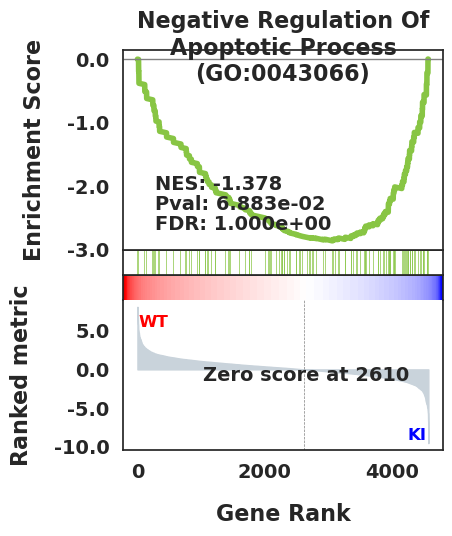

In [50]:
terms = res_BP.res2d.Term
axs = res_BP.plot(terms=terms[3]) # v1.0.5

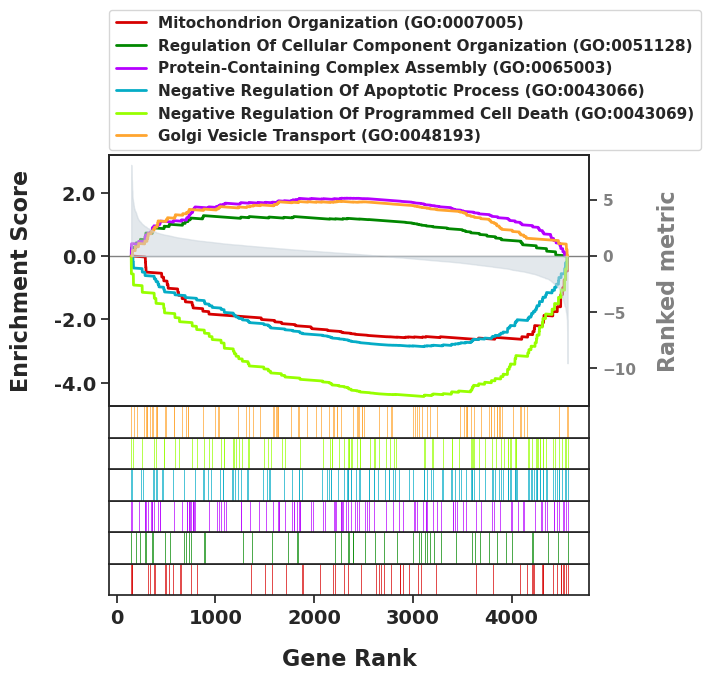

In [51]:
axs = res_BP.plot(terms=terms[:6])

In [52]:
res_MF = gp.gsea(data=pd.DataFrame(adata_subset.layers["normalized_expression_log"],columns=list(adata_subset.var_names.str.upper()),index=adata_subset.obs.index).T, # row -> genes, column-> samples
        gene_sets="GO_Molecular_Function_2023",
        cls=adata_subset.obs.Condition,
        permutation_num=1000,
        min_size=40,
        permutation_type='phenotype',
        outdir=None,
        method='s2n', # signal_to_noise
        threads= 16)

In [53]:
res_MF.res2d.head(30)


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,gsea,GTP Binding (GO:0005525),0.353649,1.476381,0.040084,1.0,0.274,19/51,29.61%,GNA11;MTG2;DNM2;RABL6;NRAS;RHOT2;DRG2;ARL3;TUB...
1,gsea,Guanyl Ribonucleotide Binding (GO:0032561),0.340728,1.409971,0.067623,1.0,0.349,19/54,29.61%,GNA11;MTG2;DNM2;RABL6;NRAS;RHOT2;DRG2;ARL3;TUB...
2,gsea,Ubiquitin Protein Ligase Binding (GO:0031625),-0.335215,-1.354726,0.082305,1.0,0.438413,46/103,28.41%,UBE2D3;UBE2W;ATXN3;MAGEA2;MAP1LC3A;TSG101;CDKN...
3,gsea,Ubiquitin-Like Protein Ligase Binding (GO:0044...,-0.311534,-1.313562,0.103659,1.0,0.482255,51/110,32.70%,UBE2D3;UBE2W;ATXN3;MAGEA2;MAP1LC3A;TSG101;CDKN...
4,gsea,Purine Ribonucleoside Triphosphate Binding (GO...,0.278558,1.252383,0.192843,1.0,0.517,49/129,36.97%,GNA11;MTG2;DNM2;STK11;RABL6;NRAS;SRPK1;PPP5C;R...
5,gsea,GTPase Activity (GO:0003924),0.264575,1.23236,0.128514,1.0,0.54,32/65,46.84%,GNA11;MTG2;DNM2;NRAS;RHOT2;DRG2;RAB23;RAB1B;GF...
6,gsea,Ribonucleoside Triphosphate Phosphatase Activi...,0.259579,1.208003,0.15213,1.0,0.568,33/67,46.84%,GNA11;MTG2;DNM2;NRAS;RHOT2;DRG2;RAB23;RAB1B;GF...
7,gsea,Calcium Ion Binding (GO:0005509),0.286844,1.207314,0.201597,0.882616,0.57,21/43,48.08%,CIB1;MAN1B1;PLA2G2C;PAM;SYT11;LETM1;EFCAB11;PP...
8,gsea,Adenyl Ribonucleotide Binding (GO:0032559),0.300892,1.150195,0.276371,0.924348,0.643,41/88,43.40%,STK11;SRPK1;PPP5C;IGHMBP2;MARK2;MKNK1;ABCB6;GA...
9,gsea,Endopeptidase Activity (GO:0004175),0.307117,1.146635,0.273279,0.817743,0.65,26/47,46.79%,PCSK4;MIPEP;USP20;THOP1;USP46;RHBDD3;ADAM2;PIT...


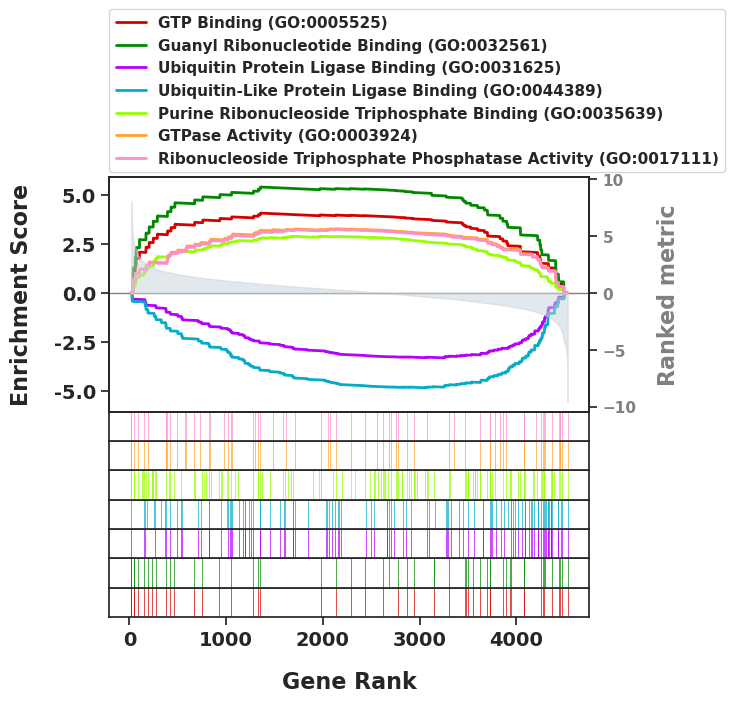

In [54]:
terms = res_MF.res2d.Term
axs = res_MF.plot(terms=terms[:7])

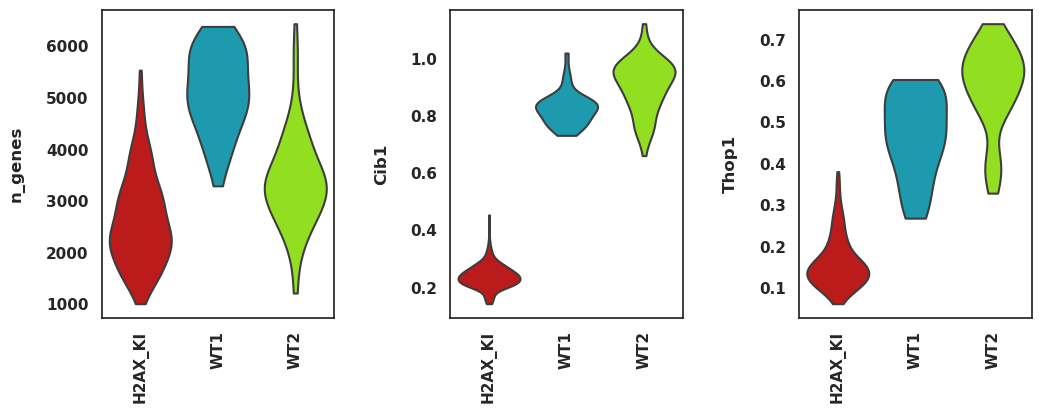

In [55]:
genes = ['n_genes', 'Cib1', 'Thop1']

# Create your own figure and axes: 1 row, 3 columns
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(genes),
    figsize=(12, 4),              # wider figure for horizontal layout
    constrained_layout=False,
    gridspec_kw={'wspace': 0.5}   # horizontal spacing between subplots
)

for ax, gene in zip(axes, genes):
    sc.pl.violin(
        subset,
        [gene],                 
        groupby='Group',
        jitter=0.4,
        rotation=90,
        stripplot=False,
        multi_panel=False,      
        show=False,
        ax=ax
    )

plt.show()


In [56]:
list_genes= pd.read_csv("/sas/sara/scRNAseq/pendas/tables/Selected_genes.txt",sep="\t")
list_genes

,Genes,Category
0,Spo11,DSB formation & end processing
1,Top6bl,DSB formation & end processing
2,Prdm9,DSB formation & end processing
3,Mei4,DSB formation & end processing
4,Rec114,DSB formation & end processing
...,...,...
146,Macroh2a1,Histones
147,Macroh2a2,Histones
148,H3f3a,Histones
149,H3f3b,Histones


In [57]:
len(set(list_genes["Genes"]) - set(adata.var_names))

107

In [58]:
de_sig = de_df[(de_df["pvals_adj"]<0.1) & (abs(de_df["logfoldchanges"]>0.5))]
de_sig

,names,scores,logfoldchanges,pvals,pvals_adj
0,Yeats4,135.159637,2.369942,1.660902e-167,2.638343e-164
1,Cox5a,113.714447,3.664283,1.450653e-114,1.772586e-112
2,Tomm20,105.153397,2.722853,1.153445e-127,2.893021e-125
3,Mpc2,97.958145,2.510239,4.480416e-172,1.067571e-168
4,Trappc6b,89.067482,2.030474,4.327181e-146,2.577648e-143
...,...,...,...,...,...
3369,Adam23,2.161645,0.738128,3.190282e-02,3.682521e-02
3373,Hlf,2.154401,0.538045,3.291476e-02,3.795192e-02
3401,Eif2c5,2.035629,0.823604,4.362643e-02,4.994637e-02
3439,Phlda2,1.924004,0.803132,5.603847e-02,6.356072e-02


In [59]:
overlap = set(de_sig["names"]) & set(list_genes["Genes"])
overlap

{'Cenpa', 'Dmc1', 'H1f0', 'H2afx', 'Mei4', 'Mnd1', 'Rpa2', 'Uimc1'}

In [60]:
list_genes[list_genes["Genes"].isin(overlap)]

,Genes,Category
3,Mei4,DSB formation & end processing
13,Dmc1,Strand invasion & HR machinery
16,Mnd1,Strand invasion & HR machinery
18,Rpa2,Strand invasion & HR machinery
57,Uimc1,DNA damage response kinases & mediators
140,H1f0,Histones
143,H2afx,Histones
150,Cenpa,Histones


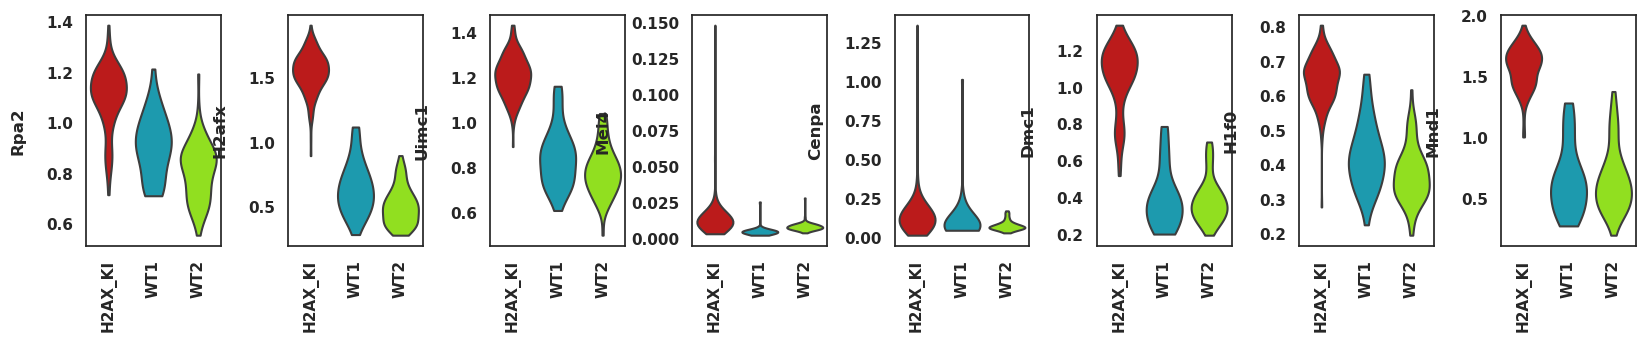

In [61]:

# Create your own figure and axes: 1 row, 3 columns
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(list(overlap)),
    figsize=(20, 3),              # wider figure for horizontal layout
    constrained_layout=False,
    gridspec_kw={'wspace': 0.5}   # horizontal spacing between subplots
)

for ax, gene in zip(axes, list(overlap)):
    sc.pl.violin(
        subset,
        [gene],                 
        groupby='Group',
        jitter=0.4,
        rotation=90,
        stripplot=False,
        multi_panel=False,      
        show=False,
        ax=ax
    )

plt.show()


## Compare mutants

In [62]:
palette_mut={"RNF212_KO":"#4A4063",
 "SIX6_D_Cterm":'#CD5334'}
sns.color_palette(palette_mut.values())

[(0.2901960784313726, 0.25098039215686274, 0.38823529411764707),
 (0.803921568627451, 0.3254901960784314, 0.20392156862745098)]

In [63]:
labels=["MII","MI"]
groups=["SIX6_D_Cterm","RNF212_KO"]

In [64]:
subset = adata[(adata.obs["manually_annotation"].isin(labels)) & (adata.obs["Group"].isin(groups))]
subset

View of AnnData object with n_obs × n_vars = 441 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_

You need to balance the number of cell per condition of sample to avoid that one outlier take too much protagonism

In [65]:
np.random.seed(42)

samples = subset.obs['Sample'].unique() 

selected_cells = []

for sample in samples:
    sample_cells = subset.obs[subset.obs['Sample'] == sample].index  # Obtén las células de este sample
    if len(sample_cells) > 100:
        # Selecciona 1000 células de forma aleatoria
        selected = np.random.choice(sample_cells, size=100, replace=False)
    else:
        # Si hay menos de 1000 células, selecciona todas
        selected = sample_cells
    selected_cells.extend(selected)

# Crea un nuevo AnnData con las células seleccionadas
adata_subset = subset[selected_cells].copy()

# Mezcla las células seleccionadas de forma aleatoria
adata_subset = adata_subset[np.random.permutation(adata_subset.n_obs)].copy()
adata_subset

AnnData object with n_obs × n_vars = 200 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1', 'lei

In [66]:
adata_subset.obs

,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,leiden_2_1.6,manually_annotation,leiden_S_0.1,leiden_S_0.2,leiden_S_0.4,leiden_S_0.6,leiden_S_0.8,leiden_S_1,leiden_S_1.2,leiden_S_1.4
GTTTGGAAGTGATCGG-1-0-0,SI-TT-A1,SIX6_D_Cterm,4905.0,32647.0,4902.0,32647,457.0,1.399822,2372.0,7.265599,...,17,MI,10,10,10,10,10,10,10,10
TACATTCCAAATACAG-1-0-0,SI-TT-A1,SIX6_D_Cterm,4383.0,22778.0,4378.0,22778,299.0,1.312670,1590.0,6.980420,...,17,MI,10,10,10,10,10,10,10,10
GCACATAGTTGGAGAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,5622.0,46189.0,5613.0,46189,774.0,1.675724,3197.0,6.921561,...,28,MI,17,17,17,17,17,17,17,17
TGAGGGAAGGCTCTCG-1-4-0,SI-TT-H12,RNF212_KO,6258.0,62773.0,6247.0,62773,1002.0,1.596228,4382.0,6.980708,...,17,MI,10,10,10,10,10,10,10,10
AACCAACCAGTCAACT-1-0-0,SI-TT-A1,SIX6_D_Cterm,4197.0,17818.0,4190.0,17818,418.0,2.345942,1194.0,6.701089,...,17,MI,10,10,10,10,10,10,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CATACAGTCTATTTCG-1-4-0,SI-TT-H12,RNF212_KO,6029.0,53322.0,6026.0,53322,645.0,1.209632,3648.0,6.841454,...,17,MI,10,10,10,10,10,10,10,10
CGGCAGTAGGGTCAAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,3711.0,15359.0,3711.0,15359,151.0,0.983137,1058.0,6.888469,...,17,MI,10,10,10,10,10,10,10,10
CCGAACGGTGTAGCAG-1-0-0,SI-TT-A1,SIX6_D_Cterm,3192.0,11800.0,3191.0,11800,158.0,1.338983,902.0,7.644068,...,28,MI,17,17,17,17,17,17,17,17
AAGCGAGGTAAGAACT-1-0-0,SI-TT-A1,SIX6_D_Cterm,3395.0,13814.0,3395.0,13814,304.0,2.200666,1052.0,7.615463,...,28,MI,17,17,17,17,17,17,17,17


In [67]:
sc.tl.rank_genes_groups(adata_subset, groupby="Group",layer="normalized_expression_log")

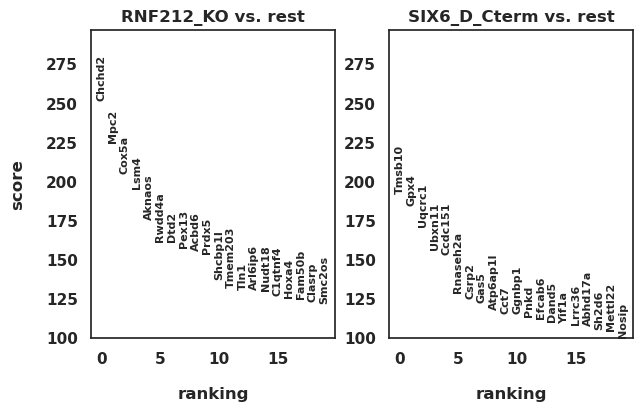

In [68]:
sc.pl.rank_genes_groups(adata_subset)

In [69]:
de_df = sc.get.rank_genes_groups_df(adata_subset, group="RNF212_KO")
de_df

,names,scores,logfoldchanges,pvals,pvals_adj
0,Chchd2,251.356369,3.629580,5.083011e-204,1.211154e-200
1,Mpc2,224.719177,3.698056,2.588993e-166,1.121623e-163
2,Cox5a,205.081635,3.335495,8.276833e-168,3.944325e-165
3,Lsm4,195.202759,3.557496,1.518672e-147,2.783550e-145
4,Aknaos,175.256149,3.571823,5.417767e-132,5.612689e-130
...,...,...,...,...,...
9526,Ccdc151,-153.170166,-1.976740,4.644413e-161,1.301938e-158
9527,Ubxn11,-156.137482,-2.854463,5.398656e-127,4.808841e-125
9528,Uqcrc1,-170.992859,-2.952900,1.343908e-196,2.134797e-193
9529,Gpx4,-184.705795,-2.422147,2.547998e-223,1.214248e-219


In [70]:
de_df.to_csv(save_dir+"/tables/de_genes_"+'_'.join(labels)+"_"+"_".join(groups)+".csv")
de_df

,names,scores,logfoldchanges,pvals,pvals_adj
0,Chchd2,251.356369,3.629580,5.083011e-204,1.211154e-200
1,Mpc2,224.719177,3.698056,2.588993e-166,1.121623e-163
2,Cox5a,205.081635,3.335495,8.276833e-168,3.944325e-165
3,Lsm4,195.202759,3.557496,1.518672e-147,2.783550e-145
4,Aknaos,175.256149,3.571823,5.417767e-132,5.612689e-130
...,...,...,...,...,...
9526,Ccdc151,-153.170166,-1.976740,4.644413e-161,1.301938e-158
9527,Ubxn11,-156.137482,-2.854463,5.398656e-127,4.808841e-125
9528,Uqcrc1,-170.992859,-2.952900,1.343908e-196,2.134797e-193
9529,Gpx4,-184.705795,-2.422147,2.547998e-223,1.214248e-219


In [71]:
de_df.head(30)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Chchd2,251.356369,3.629580,5.083011e-204,1.211154e-200
1,Mpc2,224.719177,3.698056,2.588993e-166,1.121623e-163
2,Cox5a,205.081635,3.335495,8.276833e-168,3.944325e-165
3,Lsm4,195.202759,3.557496,1.518672e-147,2.783550e-145
4,Aknaos,175.256149,3.571823,5.417767e-132,5.612689e-130
5,Rwdd4a,161.378036,2.009108,1.902866e-201,3.627243e-198
6,Dtd2,161.373703,2.860845,4.366878e-140,5.780654e-138
7,Pex13,157.677704,2.335415,1.213401e-157,3.043401e-155
8,Acbd6,155.862457,2.136203,1.766101e-204,5.610904e-201
9,Prdx5,153.927444,2.996055,2.172142e-168,1.089615e-165


In [72]:
top = de_df.sort_values(by="scores").head(100)
tail = de_df.sort_values(by="scores").tail(100)

de_top = pd.concat([top, tail], ignore_index=True)
de_top

,names,scores,logfoldchanges,pvals,pvals_adj
0,Tmsb10,-192.440491,-2.728338,1.143614e-224,1.089979e-220
1,Gpx4,-184.705795,-2.422147,2.547998e-223,1.214248e-219
2,Uqcrc1,-170.992859,-2.952900,1.343908e-196,2.134797e-193
3,Ubxn11,-156.137482,-2.854463,5.398656e-127,4.808841e-125
4,Ccdc151,-153.170166,-1.976740,4.644413e-161,1.301938e-158
...,...,...,...,...,...
195,Aknaos,175.256149,3.571823,5.417767e-132,5.612689e-130
196,Lsm4,195.202759,3.557496,1.518672e-147,2.783550e-145
197,Cox5a,205.081635,3.335495,8.276833e-168,3.944325e-165
198,Mpc2,224.719177,3.698056,2.588993e-166,1.121623e-163


If you want to check the expression of a specific gene change the label below

In [73]:
gene="Atp6ap1l"

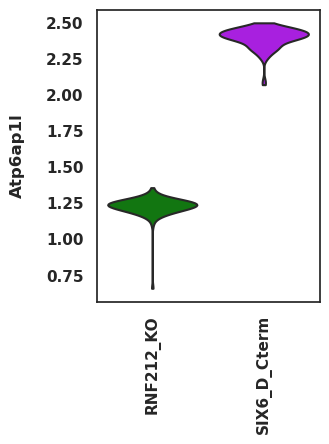

In [74]:
plt.rcParams.update({"axes.labelpad":15})

sc.pl.violin(adata_subset, groupby="Group",keys=gene, rotation=90, multi_panel=True, stripplot=False,return_fig=True)


## GSEA

In [75]:
import gseapy as gp
names = gp.get_library_name()
print(names)

['ARCHS4_Cell-lines', 'ARCHS4_IDG_Coexp', 'ARCHS4_Kinases_Coexp', 'ARCHS4_TFs_Coexp', 'ARCHS4_Tissues', 'Achilles_fitness_decrease', 'Achilles_fitness_increase', 'Aging_Perturbations_from_GEO_down', 'Aging_Perturbations_from_GEO_up', 'Allen_Brain_Atlas_10x_scRNA_2021', 'Allen_Brain_Atlas_down', 'Allen_Brain_Atlas_up', 'Azimuth_2023', 'Azimuth_Cell_Types_2021', 'BioCarta_2013', 'BioCarta_2015', 'BioCarta_2016', 'BioPlanet_2019', 'BioPlex_2017', 'CCLE_Proteomics_2020', 'CM4AI_U2OS_Protein_Localization_Assemblies', 'COMPARTMENTS_Curated_2025', 'COMPARTMENTS_Experimental_2025', 'CORUM', 'COVID-19_Related_Gene_Sets', 'COVID-19_Related_Gene_Sets_2021', 'Cancer_Cell_Line_Encyclopedia', 'CellMarker_2024', 'CellMarker_Augmented_2021', 'ChEA_2013', 'ChEA_2015', 'ChEA_2016', 'ChEA_2022', 'Chromosome_Location', 'Chromosome_Location_hg19', 'ClinVar_2019', 'ClinVar_2025', 'DGIdb_Drug_Targets_2024', 'DSigDB', 'Data_Acquisition_Method_Most_Popular_Genes', 'DepMap_CRISPR_GeneDependency_CellLines_2023',

In [76]:
rnk = pd.DataFrame(de_top["scores"].to_list(), index =de_top["names"].to_list())
rnk

,0
Tmsb10,-192.440491
Gpx4,-184.705795
Uqcrc1,-170.992859
Ubxn11,-156.137482
Ccdc151,-153.170166
...,...
Aknaos,175.256149
Lsm4,195.202759
Cox5a,205.081635
Mpc2,224.719177


In [77]:
rnk[50:100]

,0
Art1,-74.459702
Itgb1bp1,-74.343674
Exosc5,-74.281517
Rims3,-73.945381
Mgst3,-73.562286
Josd2,-73.439293
Ldlrad4,-73.100372
Dnajc4,-72.881432
Zfp296,-72.649994
Tmem120a,-72.384048


In [78]:
enr = gp.enrichr(gene_list=list(de_top["names"]), # or "./tests/data/gene_list.txt",
                 gene_sets=['KEGG_2019_Mouse'],
                 organism='mouse', # don't forget to set organism to the one you desired! e.g. Yeast
                 outdir=None, # don't write to disk
                )
enr.results["n_genes"] = enr.results["Overlap"].str.split("/",expand=True)[0].astype(int)
enr.results["% genes"] = enr.results["n_genes"] / enr.results["Overlap"].str.split("/",expand=True)[1].astype(int)

enr.results[(enr.results["n_genes"]>4)  ].sort_values(by="Combined Score",ascending=False).head(25)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,n_genes,% genes
0,KEGG_2019_Mouse,Huntington disease,8/192,0.000717,0.069510,0,0,4.442029,32.164683,NDUFA11;UQCRC1;NDUFA4L2;AP2S1;SDHC;IFT57;POLR2...,8,0.041667
1,KEGG_2019_Mouse,Oxidative phosphorylation,6/134,0.002309,0.111997,0,0,4.753222,28.856070,NDUFA11;UQCRC1;NDUFA4L2;SDHC;ATP6V0E2;COX5A,6,0.044776
2,KEGG_2019_Mouse,Non-alcoholic fatty liver disease (NAFLD),6/151,0.004168,0.134773,0,0,4.192321,22.975030,NDUFA11;DDIT3;UQCRC1;NDUFA4L2;SDHC;COX5A,6,0.039735
3,KEGG_2019_Mouse,Ubiquitin mediated proteolysis,5/138,0.012647,0.290347,0,0,3.791594,16.570621,CDC20;UBE2S;KEAP1;UBA2;UBE2M,5,0.036232
4,KEGG_2019_Mouse,Parkinson disease,5/144,0.014966,0.290347,0,0,3.626822,15.239735,NDUFA11;UQCRC1;NDUFA4L2;SDHC;COX5A,5,0.034722
6,KEGG_2019_Mouse,Alzheimer disease,5/175,0.031473,0.436123,0,0,2.960784,10.240263,NDUFA11;UQCRC1;NDUFA4L2;SDHC;COX5A,5,0.028571
5,KEGG_2019_Mouse,Thermogenesis,6/231,0.028947,0.436123,0,0,2.690722,9.531293,KLB;NDUFA11;UQCRC1;NDUFA4L2;SDHC;COX5A,6,0.025974


In [79]:
enr = gp.enrichr(gene_list=list(de_top["names"]), # or "./tests/data/gene_list.txt",
                 gene_sets=['GO_Biological_Process_2023'],
                 organism='mouse', # don't forget to set organism to the one you desired! e.g. Yeast
                 outdir=None, # don't write to disk
                )
enr.results["n_genes"] = enr.results["Overlap"].str.split("/",expand=True)[0].astype(int)
enr.results["% genes"] = enr.results["n_genes"] / enr.results["Overlap"].str.split("/",expand=True)[1].astype(int)

enr.results[(enr.results["n_genes"]>4)  ].sort_values(by="Combined Score",ascending=False).head(25)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,n_genes,% genes
0,GO_Biological_Process_2023,Mitochondrial Translation (GO:0032543),6/98,0.000455,0.155509,0,0,6.625280,50.980606,MRPL2;MRPS11;MRPS34;MRPL38;MRPL48;MRPL57,6,0.061224
1,GO_Biological_Process_2023,Mitochondrial Gene Expression (GO:0140053),6/103,0.000593,0.155509,0,0,6.282177,46.675055,MRPL2;MRPS11;MRPS34;MRPL38;MRPL48;MRPL57,6,0.058252
5,GO_Biological_Process_2023,Macromolecule Modification (GO:0043412),5/81,0.001317,0.225018,0,0,6.654521,44.134531,SERP1;UBE2S;MCRS1;LCMT1;UBE2M,5,0.061728
11,GO_Biological_Process_2023,Ubiquitin-Dependent Protein Catabolic Process ...,10/367,0.003974,0.290228,0,0,2.866431,15.845859,PSMD8;KLHDC3;NDFIP1;GID4;UBXN11;UBE2S;DDIT3;CH...,10,0.027248
21,GO_Biological_Process_2023,Translation (GO:0006412),7/234,0.009359,0.353422,0,0,3.127320,14.609061,MRPL2;MRPS11;MRPS34;MRPL38;MRPL48;RPL8;MRPL57,7,0.029915
45,GO_Biological_Process_2023,protein-RNA Complex Assembly (GO:0022618),5/150,0.017555,0.375591,0,0,3.475685,14.050149,NUDT21;EIF3K;MRPS11;RPL10L;LSM4,5,0.033333
37,GO_Biological_Process_2023,Endomembrane System Organization (GO:0010256),6/196,0.014154,0.371383,0,0,3.192078,13.590988,SERP1;STX17;LMNA;CHMP2B;VPS4A;BNIP1,6,0.030612
38,GO_Biological_Process_2023,Golgi Vesicle Transport (GO:0048193),6/197,0.014481,0.371383,0,0,3.175204,13.446623,STX17;TRAPPC5;BNIP1;ATP9B;YIF1A;YIF1B,6,0.030457
41,GO_Biological_Process_2023,Proteasome-Mediated Ubiquitin-Dependent Protei...,8/319,0.015218,0.371383,0,0,2.611066,10.928098,CDC20;PSMD8;KLHDC3;GID4;UBXN11;UBE2S;DDIT3;UBXN8,8,0.025078
98,GO_Biological_Process_2023,Regulation Of Programmed Cell Death (GO:0043067),5/195,0.046517,0.375591,0,0,2.646424,8.119080,MRGBP;EPC1;YEATS4;IFT57;LCMT1,5,0.025641


In [80]:
for x in enr.results[(enr.results["n_genes"]>4)  ].sort_values(by="Combined Score",ascending=False).head(7)["Term"]:
    print(x)

Mitochondrial Translation (GO:0032543)
Mitochondrial Gene Expression (GO:0140053)
Macromolecule Modification (GO:0043412)
Ubiquitin-Dependent Protein Catabolic Process (GO:0006511)
Translation (GO:0006412)
protein-RNA Complex Assembly (GO:0022618)
Endomembrane System Organization (GO:0010256)


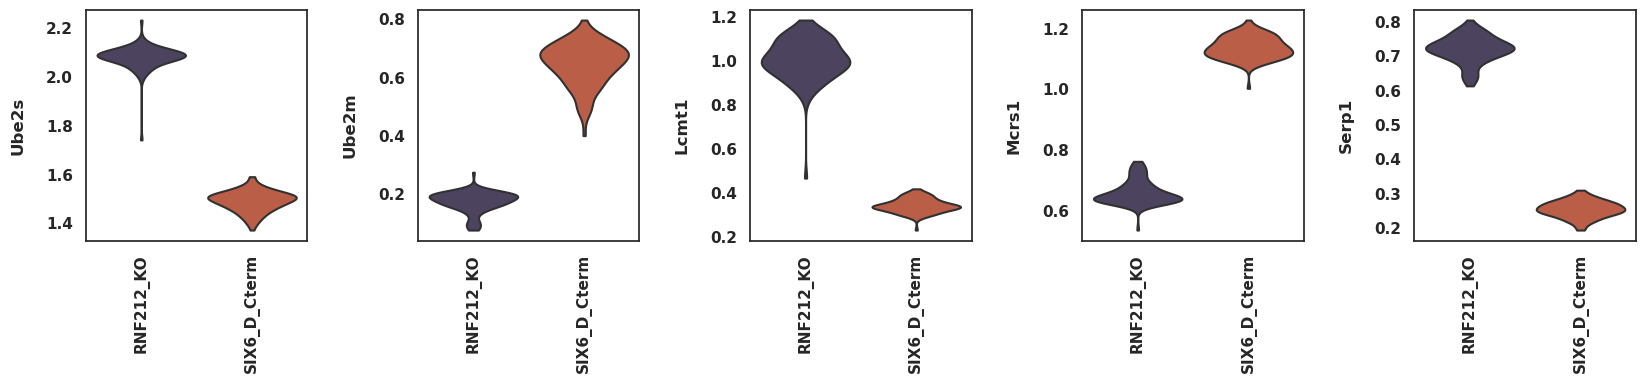

In [81]:

# Create your own figure and axes: 1 row, 3 columns
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(["Ube2s","Ube2m","Lcmt1","Mcrs1","Serp1"	]),
    figsize=(20, 3),              # wider figure for horizontal layout
    constrained_layout=False,
    gridspec_kw={'wspace': 0.5}   # horizontal spacing between subplots
)

for ax, gene in zip(axes, ["Ube2s","Ube2m","Lcmt1","Mcrs1","Serp1"	]):
    sc.pl.violin(
        adata_subset,
        [gene],                 
        groupby='Group',
        palette=palette_mut,
        jitter=0.4,
        rotation=90,
        stripplot=False,
        multi_panel=False,      
        show=False,
        ax=ax
    )

plt.show()

In [82]:
adata_subset.layers

Layers with keys: counts, normalized_expression, normalized_expression_log

In [83]:
data_expr = pd.DataFrame(adata_subset.layers["normalized_expression_log"])

data_expr.columns = adata_subset.var_names
data_expr.index = adata_subset.obs_names
data_expr.head(5)

,Rp1,Sox17,Tcea1,Atp6v1h,Rb1cc1,Pcmtd1,Sntg1,Rrs1,Adhfe1,Mybl1,...,mt-Co3,mt-Nd3,mt-Nd4l,mt-Nd4,mt-Nd5,mt-Nd6,mt-Cytb,AC168977.1,AC132444.6,Vamp7
GTTTGGAAGTGATCGG-1-0-0,0.162339,0.123108,0.049562,0.421443,2.001070,0.003656,0.008114,0.167953,0.012134,0.513310,...,4.095235,0.772621,0.269312,2.098425,0.893368,0.040527,2.119004,0.003422,0.005801,0.005643
TACATTCCAAATACAG-1-0-0,0.167638,0.156134,0.057864,0.430798,2.060933,0.003953,0.006946,0.149314,0.011688,0.563176,...,3.926846,0.665122,0.275536,1.953193,0.863983,0.054952,1.935794,0.003122,0.007036,0.006388
GCACATAGTTGGAGAC-1-0-0,0.130859,0.172328,0.067151,0.382071,1.935812,0.005193,0.010446,0.090767,0.010620,0.611174,...,4.006887,0.858485,0.333591,2.160359,0.942717,0.061267,2.183701,0.003657,0.006853,0.009482
TGAGGGAAGGCTCTCG-1-4-0,0.241827,0.127831,0.072140,0.442725,2.107591,0.006541,0.010992,0.146632,0.007925,0.383631,...,3.966722,0.544495,0.270333,2.037390,1.018548,0.102983,2.053150,0.004504,0.009210,0.007755
AACCAACCAGTCAACT-1-0-0,0.250096,0.132240,0.070513,0.505630,2.241718,0.006200,0.007166,0.237292,0.018927,0.675136,...,4.294774,0.967373,0.453734,2.346722,1.234486,0.135682,2.367299,0.003658,0.012189,0.009105


In [84]:
adata_subset.obs

,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,leiden_2_1.6,manually_annotation,leiden_S_0.1,leiden_S_0.2,leiden_S_0.4,leiden_S_0.6,leiden_S_0.8,leiden_S_1,leiden_S_1.2,leiden_S_1.4
GTTTGGAAGTGATCGG-1-0-0,SI-TT-A1,SIX6_D_Cterm,4905.0,32647.0,4902.0,32647,457.0,1.399822,2372.0,7.265599,...,17,MI,10,10,10,10,10,10,10,10
TACATTCCAAATACAG-1-0-0,SI-TT-A1,SIX6_D_Cterm,4383.0,22778.0,4378.0,22778,299.0,1.312670,1590.0,6.980420,...,17,MI,10,10,10,10,10,10,10,10
GCACATAGTTGGAGAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,5622.0,46189.0,5613.0,46189,774.0,1.675724,3197.0,6.921561,...,28,MI,17,17,17,17,17,17,17,17
TGAGGGAAGGCTCTCG-1-4-0,SI-TT-H12,RNF212_KO,6258.0,62773.0,6247.0,62773,1002.0,1.596228,4382.0,6.980708,...,17,MI,10,10,10,10,10,10,10,10
AACCAACCAGTCAACT-1-0-0,SI-TT-A1,SIX6_D_Cterm,4197.0,17818.0,4190.0,17818,418.0,2.345942,1194.0,6.701089,...,17,MI,10,10,10,10,10,10,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CATACAGTCTATTTCG-1-4-0,SI-TT-H12,RNF212_KO,6029.0,53322.0,6026.0,53322,645.0,1.209632,3648.0,6.841454,...,17,MI,10,10,10,10,10,10,10,10
CGGCAGTAGGGTCAAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,3711.0,15359.0,3711.0,15359,151.0,0.983137,1058.0,6.888469,...,17,MI,10,10,10,10,10,10,10,10
CCGAACGGTGTAGCAG-1-0-0,SI-TT-A1,SIX6_D_Cterm,3192.0,11800.0,3191.0,11800,158.0,1.338983,902.0,7.644068,...,28,MI,17,17,17,17,17,17,17,17
AAGCGAGGTAAGAACT-1-0-0,SI-TT-A1,SIX6_D_Cterm,3395.0,13814.0,3395.0,13814,304.0,2.200666,1052.0,7.615463,...,28,MI,17,17,17,17,17,17,17,17


In [85]:
data_expr[["Group","Sample","Condition"]] = adata_subset.obs[["Group","Sample","Condition"]]
data_expr

,Rp1,Sox17,Tcea1,Atp6v1h,Rb1cc1,Pcmtd1,Sntg1,Rrs1,Adhfe1,Mybl1,...,mt-Nd4,mt-Nd5,mt-Nd6,mt-Cytb,AC168977.1,AC132444.6,Vamp7,Group,Sample,Condition
GTTTGGAAGTGATCGG-1-0-0,0.162339,0.123108,0.049562,0.421443,2.001070,0.003656,0.008114,0.167953,0.012134,0.513310,...,2.098425,0.893368,0.040527,2.119004,0.003422,0.005801,0.005643,SIX6_D_Cterm,SI-TT-A1,KI
TACATTCCAAATACAG-1-0-0,0.167638,0.156134,0.057864,0.430798,2.060933,0.003953,0.006946,0.149314,0.011688,0.563176,...,1.953193,0.863983,0.054952,1.935794,0.003122,0.007036,0.006388,SIX6_D_Cterm,SI-TT-A1,KI
GCACATAGTTGGAGAC-1-0-0,0.130859,0.172328,0.067151,0.382071,1.935812,0.005193,0.010446,0.090767,0.010620,0.611174,...,2.160359,0.942717,0.061267,2.183701,0.003657,0.006853,0.009482,SIX6_D_Cterm,SI-TT-A1,KI
TGAGGGAAGGCTCTCG-1-4-0,0.241827,0.127831,0.072140,0.442725,2.107591,0.006541,0.010992,0.146632,0.007925,0.383631,...,2.037390,1.018548,0.102983,2.053150,0.004504,0.009210,0.007755,RNF212_KO,SI-TT-H12,KI
AACCAACCAGTCAACT-1-0-0,0.250096,0.132240,0.070513,0.505630,2.241718,0.006200,0.007166,0.237292,0.018927,0.675136,...,2.346722,1.234486,0.135682,2.367299,0.003658,0.012189,0.009105,SIX6_D_Cterm,SI-TT-A1,KI
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CATACAGTCTATTTCG-1-4-0,0.262641,0.146082,0.089718,0.463062,2.202711,0.008409,0.011236,0.148693,0.008574,0.418060,...,1.918903,1.003374,0.134205,1.886445,0.004648,0.011511,0.008977,RNF212_KO,SI-TT-H12,KI
CGGCAGTAGGGTCAAC-1-0-0,0.138217,0.163561,0.050573,0.385690,1.934987,0.002417,0.005597,0.105398,0.007084,0.506843,...,1.684696,0.642064,0.033140,1.527754,0.002577,0.004069,0.004064,SIX6_D_Cterm,SI-TT-A1,KI
CCGAACGGTGTAGCAG-1-0-0,0.073549,0.130353,0.062100,0.348580,1.616771,0.008119,0.010541,0.074859,0.007572,0.458836,...,2.074835,0.761115,0.026526,2.225115,0.003220,0.003790,0.007679,SIX6_D_Cterm,SI-TT-A1,KI
AAGCGAGGTAAGAACT-1-0-0,0.099317,0.139152,0.045080,0.347978,1.739258,0.003178,0.006130,0.083248,0.007005,0.558989,...,2.012250,0.776600,0.030920,2.074462,0.002648,0.003355,0.004347,SIX6_D_Cterm,SI-TT-A1,KI


In [86]:
gene="Serp1"


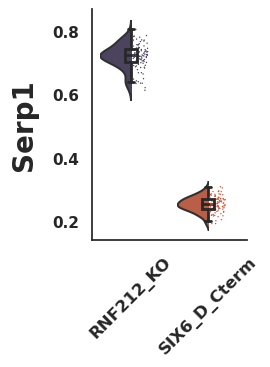

In [87]:
#plt.rcParams['figure.figsize'] =2,3

plt.figure(figsize=(2, 3))

ax = sns.violinplot(x="Group",y=gene, data=data_expr, hue="Group", dodge=False,
                    palette=palette_mut,
                    scale="width", inner=None)
xlim = ax.get_xlim()
ylim = ax.get_ylim()
for violin in ax.collections:
    bbox = violin.get_paths()[0].get_extents()
    x0, y0, width, height = bbox.bounds
    violin.set_clip_path(plt.Rectangle((x0, y0), width / 2, height, transform=ax.transData))


old_len_collections = len(ax.collections)
sns.stripplot(x="Group",y=gene, data=data_expr, hue="Group", palette=palette_mut, dodge=False, ax=ax,s=1)
for dots in ax.collections[old_len_collections:]:
    dots.set_offsets(dots.get_offsets() + np.array([0.12, 0]))
sns.boxplot(x="Group",y=gene, data=data_expr, saturation=1, showfliers=False,
            width=0.15, boxprops={'zorder': 3, 'facecolor': 'none'}, ax=ax,linewidth=2)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.xlabel("")
plt.xticks(weight="bold",size=12,rotation=45)
plt.ylabel(gene,weight="bold",size=20,labelpad=10)
sns.despine()
plt.gca().get_legend().remove()

#ax.legend_.remove()
plt.show()

In [88]:
enr = gp.enrichr(gene_list=list(de_top["names"]), # or "./tests/data/gene_list.txt",
                 gene_sets=['GO_Molecular_Function_2023'],
                 organism='mouse', # don't forget to set organism to the one you desired! e.g. Yeast
                 outdir=None, # don't write to disk
                )
enr.results["n_genes"] = enr.results["Overlap"].str.split("/",expand=True)[0].astype(int)
enr.results["% genes"] = enr.results["n_genes"] / enr.results["Overlap"].str.split("/",expand=True)[1].astype(int)

enr.results[(enr.results["n_genes"]>4)  ].sort_values(by="Combined Score",ascending=False).head(25)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,n_genes,% genes
45,GO_Molecular_Function_2023,RNA Binding (GO:0003723),19/1411,0.114262,0.467590,0,0,1.388169,3.011302,CHTOP;RPS19BP1;MCRS1;MRPS11;CCDC124;NOSIP;DDX5...,19,0.013466
95,GO_Molecular_Function_2023,GTPase Regulator Activity (GO:0030695),6/424,0.251406,0.513551,0,0,1.434075,1.980008,GRTP1;TBC1D7;PDE6D;ITGB1BP1;RGL2;GIT1,6,0.014151
145,GO_Molecular_Function_2023,Purine Ribonucleoside Triphosphate Binding (GO...,5/476,0.518799,0.718781,0,0,1.052262,0.690535,ARL4A;GUK1;VPS4A;UBA2;TOP1,5,0.010504
178,GO_Molecular_Function_2023,DNA Binding (GO:0003677),6/846,0.854353,0.965621,0,0,0.698085,0.109886,TIGD2;CHCHD2;PHF1;DDIT3;POLL;TOP1,6,0.007092
200,GO_Molecular_Function_2023,Cis-Regulatory Region Sequence-Specific DNA Bi...,5/1098,0.986945,0.993911,0,0,0.438853,0.005767,DDIT3;UBA2;TOP1;FOXP4;HOXA4,5,0.004554
201,GO_Molecular_Function_2023,RNA Polymerase II Cis-Regulatory Region Sequen...,5/1122,0.989015,0.993911,0,0,0.428873,0.004737,DDIT3;UBA2;TOP1;FOXP4;HOXA4,5,0.004456
202,GO_Molecular_Function_2023,RNA Polymerase II Transcription Regulatory Reg...,5/1225,0.994864,0.994864,0,0,0.390500,0.002011,DDIT3;UBA2;TOP1;FOXP4;HOXA4,5,0.004082


In [89]:
top = de_df.sort_values(by="scores").head(25)
tail = de_df.sort_values(by="scores").tail(25)

de_top = pd.concat([top, tail], ignore_index=True)
de_top


,names,scores,logfoldchanges,pvals,pvals_adj
0,Tmsb10,-192.440491,-2.728338,1.143614e-224,1.089979e-220
1,Gpx4,-184.705795,-2.422147,2.547998e-223,1.214248e-219
2,Uqcrc1,-170.992859,-2.952900,1.343908e-196,2.134797e-193
3,Ubxn11,-156.137482,-2.854463,5.398656e-127,4.808841e-125
4,Ccdc151,-153.170166,-1.976740,4.644413e-161,1.301938e-158
5,Rnaseh2a,-128.688400,-2.599006,5.517799e-190,7.512878e-187
6,Csrp2,-125.245750,-1.925216,6.289808e-169,3.330453e-166
7,Gas5,-122.472855,-1.525600,1.015759e-154,2.361269e-152
8,Atp6ap1l,-118.230400,-2.049361,1.357808e-185,1.617658e-182
9,Cct7,-115.627663,-1.518746,1.574066e-183,1.666935e-180


In [90]:
subset.X.shape

(441, 9531)

In [91]:
subset_reduced =  adata_subset[:, de_top["names"]]
subset_reduced


View of AnnData object with n_obs × n_vars = 200 × 50
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1'

In [92]:
matrix_de = pd.DataFrame(subset_reduced.X) 
matrix_de.columns = de_top["names"]
matrix_de

names,Tmsb10,Gpx4,Uqcrc1,Ubxn11,Ccdc151,Rnaseh2a,Csrp2,Gas5,Atp6ap1l,Cct7,...,Prdx5,Acbd6,Pex13,Dtd2,Rwdd4a,Aknaos,Lsm4,Cox5a,Mpc2,Chchd2
0,3.009168,2.692495,1.408887,0.839262,0.572757,2.237152,0.810057,1.496992,2.399168,2.758527,...,0.476017,1.113817,0.641423,0.161022,0.412823,0.070907,0.182502,0.558568,0.705110,0.601814
1,2.966197,2.649743,1.410754,0.848998,0.583840,2.276345,0.817366,1.457076,2.399028,2.775856,...,0.474548,1.089883,0.625939,0.162794,0.429798,0.076093,0.167547,0.547376,0.681603,0.591382
2,2.982391,2.684359,1.482663,0.818604,0.606481,2.272048,0.823196,1.428515,2.407908,2.682269,...,0.499607,1.044135,0.599897,0.144326,0.449493,0.071774,0.171113,0.580598,0.729806,0.630187
3,1.310343,1.233710,0.316186,0.164898,0.172839,0.856139,0.270154,0.778780,1.252544,1.807416,...,1.753964,2.287024,1.704106,0.807000,1.113994,0.614613,1.172927,2.066110,2.624205,2.386572
4,2.918556,2.628927,1.388414,0.890365,0.582527,2.216527,0.758583,1.421548,2.330010,2.750087,...,0.448033,1.076979,0.647179,0.154795,0.430946,0.072711,0.176796,0.529632,0.655478,0.609436
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,1.263469,1.209406,0.309429,0.166790,0.175976,0.854608,0.260290,0.771383,1.213493,1.830385,...,1.772499,2.291996,1.665704,0.822075,1.129600,0.650705,1.132523,2.027393,2.567661,2.345645
196,2.998597,2.695279,1.400405,0.826143,0.566926,2.317399,0.831897,1.503884,2.431318,2.777324,...,0.500059,1.104547,0.623207,0.168558,0.428779,0.086101,0.168783,0.559220,0.707101,0.576196
197,3.083881,2.746685,1.511808,0.849238,0.555248,2.432500,0.877223,1.552145,2.419756,2.738992,...,0.567266,1.122209,0.636651,0.138684,0.388626,0.082586,0.161082,0.540382,0.705607,0.600044
198,3.081558,2.748776,1.538397,0.824559,0.586518,2.396856,0.891167,1.532906,2.490942,2.743265,...,0.520841,1.049566,0.593680,0.142823,0.403100,0.071242,0.161216,0.554834,0.707142,0.608172


In [93]:
matrix_de.columns

Index(['Tmsb10', 'Gpx4', 'Uqcrc1', 'Ubxn11', 'Ccdc151', 'Rnaseh2a', 'Csrp2',
       'Gas5', 'Atp6ap1l', 'Cct7', 'Ggnbp1', 'Pnkd', 'Efcab6', 'Dand5',
       'Yif1a', 'Lrrc36', 'Abhd17a', 'Sh2d6', 'Mettl22', 'Nosip', 'Them6',
       'Rgl2', 'Pex16', 'Edf1', 'Pcyt2', 'Rnaseh2c', 'Dynlt1a', 'Chmp2b',
       'Dnajb3', 'Chchd7', 'Smc2os', 'Clasrp', 'Fam50b', 'Hoxa4', 'C1qtnf4',
       'Nudt18', 'Arl6ip6', 'Tln1', 'Tmem203', 'Shcbp1l', 'Prdx5', 'Acbd6',
       'Pex13', 'Dtd2', 'Rwdd4a', 'Aknaos', 'Lsm4', 'Cox5a', 'Mpc2', 'Chchd2'],
      dtype='object', name='names')

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.


<Figure size 350x400 with 0 Axes>

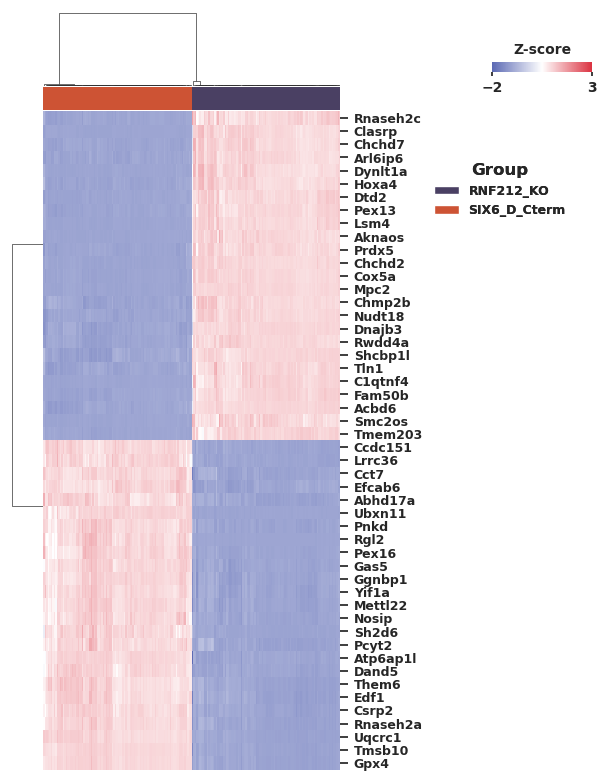

In [94]:
#subset.obs["Genotype_number"] = subset.obs["Genotype"].replace({ 'WT' : 0, 'KI' : 1 })
kws = dict(cbar_kws=dict(ticks=[-2,3],orientation='horizontal'), figsize=(5, 8))

fig = plt.figure()

sns.set(font_scale=1,context='notebook', style="white", palette=cluster_colors)


lut=palette_mut
row_colors = pd.DataFrame(subset_reduced.obs["Group"].to_list())[0].map(lut)


g=sns.clustermap(matrix_de.T, col_cluster=True,row_cluster=True,linewidths=0, cmap=red_blue, col_colors=[row_colors.to_numpy()],yticklabels=True,xticklabels=False,method="average",metric="correlation",dendrogram_ratio = 0.1,**kws,vmax=3,vmin=-2,colors_ratio=0.03,z_score=0)
handles = [Patch(facecolor=lut[name]) for name in lut]

legend_group =plt.legend(handles, lut, title='Group',bbox_to_anchor=(1.17, 0.8),fontsize=9,frameon=False,ncol=1,bbox_transform=plt.gcf().transFigure)

bbox_transform=plt.gcf().transFigure


plt.setp(g.ax_heatmap.yaxis.get_majorticklabels(), size=9)

g.ax_heatmap.set_ylabel('')

g.ax_cbar.tick_params(axis='x', length=20,labelsize="small")

g.ax_cbar.set_position([1, 0.9, 0.2, 0.012])

g.ax_cbar.set_title('Z-score', size=10)

plt.gca().add_artist(legend_group)

cbar = g.cax

cbar.xaxis.set_tick_params(size=3)

plt.savefig(save_dir+"/figures/HeatmapDE_"+'_'.join(labels)+"_"+"_".join(groups)+".png",bbox_inches="tight",dpi=600,pad_inches=0.5)


plt.show()

In [95]:
sc.pp.filter_genes(adata_subset, min_counts=30)
adata_subset

AnnData object with n_obs × n_vars = 200 × 3900
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_2_1', 'lei

In [96]:
res_BP = gp.gsea(data=pd.DataFrame(adata_subset.layers["normalized_expression_log"],columns=list(adata_subset.var_names.str.upper()),index=adata_subset.obs.index).T, # row -> genes, column-> samples
        gene_sets="GO_Biological_Process_2023",
        cls=adata_subset.obs.Group,
        permutation_num=1000,
        min_size=50,
        permutation_type='phenotype',
        outdir=None,
        method='s2n', # signal_to_noise
        threads= 16)
res_BP

In [97]:
res_BP.res2d[res_BP.res2d["ES"]>0].head(30)


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,gsea,Regulation Of Cell Migration (GO:0030334),0.566316,2.15461,0.0,0.0,0.0,10/57,8.67%,TMSB10;CIB1;LDLRAD4;HDAC1;DDRGK1;CCAR1;FUZ;BRM...
8,gsea,Positive Regulation Of Protein Phosphorylation...,0.487219,1.789734,0.0,0.027533,0.047,30/61,30.64%,CIB1;MOB3B;MAD2L2;DDRGK1;PARK7;MOB2;PGF;SLCO3A...
9,gsea,Golgi Vesicle Transport (GO:0048193),0.428695,1.735388,0.0,0.036336,0.09,25/77,24.00%,YIF1A;YIF1B;TRAPPC5;ATP9B;BNIP1;COG7;ARL3;WHAM...
12,gsea,Regulation Of Protein Phosphorylation (GO:0001...,0.43981,1.645878,0.004057,0.064619,0.184,19/50,21.67%,CIB1;MOB3B;PARK7;MOB2;PGF;SORD;SLCO3A1;INPP5K;...
13,gsea,Protein-Containing Complex Assembly (GO:0065003),0.354122,1.634771,0.007797,0.057202,0.196,37/91,37.64%,GPX4;MAPK8IP2;TRAPPC5;ITGB1BP1;AP2S1;DNAAF1;CC...
14,gsea,Positive Regulation Of Cell Population Prolife...,0.403241,1.630553,0.0,0.049447,0.204,33/69,37.72%,CIB1;ITGB1BP1;HDAC1;DDRGK1;EPCAM;PGF;CCAR1;CAP...
16,gsea,Supramolecular Fiber Organization (GO:0097435),0.425455,1.583087,0.052738,0.065983,0.257,16/53,23.31%,KATNB1;CIB1;CCDC13;MAD2L2;CRTAP;WHAMM;MYO1C;DB...
21,gsea,DNA Repair (GO:0006281),0.352508,1.510177,0.014085,0.099948,0.363,39/96,33.62%,RNASEH2A;CIB1;POLL;MAD2L2;PARK7;ACTR8;APTX;RAD...
27,gsea,Regulation Of Autophagy (GO:0010506),0.35241,1.411,0.070565,0.177249,0.505,29/60,41.00%,DDIT3;STK11;CAPNS1;USP20;WDR24;BAD;ATP6V1G1;BN...
32,gsea,DNA Metabolic Process (GO:0006259),0.326561,1.337779,0.108434,0.250328,0.627,50/102,43.62%,RNASEH2A;MCRS1;POLL;PARK7;ACTR8;TOP3A;MCM7;END...


In [98]:
res_BP.res2d["gene_set"]= "GO_Biological_Process_2023"
res_BP.res2d.head(30)


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,gene_set
0,gsea,Regulation Of Cell Migration (GO:0030334),0.566316,2.15461,0.0,0.0,0.0,10/57,8.67%,TMSB10;CIB1;LDLRAD4;HDAC1;DDRGK1;CCAR1;FUZ;BRM...,GO_Biological_Process_2023
1,gsea,Vesicle-Mediated Transport (GO:0016192),-0.436512,-2.031263,0.0,0.002894,0.002008,24/92,19.31%,CHMP2B;ARL4A;AP4S1;VPS4A;STX17;SNAPIN;TSG101;A...,GO_Biological_Process_2023
2,gsea,Regulation Of Apoptotic Process (GO:0042981),-0.414018,-2.015195,0.0,0.002894,0.003012,42/142,28.90%,PRDX5;NUGGC;YEATS4;EPC1;MRGBP;LCMT1;IFT57;EGLN...,GO_Biological_Process_2023
3,gsea,Nervous System Development (GO:0007399),-0.511772,-1.982882,0.0,0.003859,0.00502,15/54,18.67%,ITM2B;MSI2;GFRA4;ALDH1A2;ATXN10;AHI1;NDUFS2;CD...,GO_Biological_Process_2023
4,gsea,Cellular Response To Oxygen-Containing Compoun...,-0.477857,-1.914351,0.002,0.007235,0.013052,16/58,28.64%,PEX13;PRDX5;NUGGC;NEK7;MAPK3;ITPKA;RRAGD;MTOR;...,GO_Biological_Process_2023
5,gsea,Negative Regulation Of Apoptotic Process (GO:0...,-0.384637,-1.89724,0.0,0.006077,0.014056,36/92,35.18%,PRDX5;NUGGC;CDKN2D;FXN;BNIP2;PHB2;BAG1;SIX1;CO...,GO_Biological_Process_2023
6,gsea,Negative Regulation Of Programmed Cell Death (...,-0.378555,-1.84423,0.0,0.011576,0.028112,28/73,34.59%,PRDX5;NUGGC;FXN;BNIP2;PHB2;BAG1;COMP;AHI1;MDM2...,GO_Biological_Process_2023
7,gsea,Modification-Dependent Protein Catabolic Proce...,-0.462718,-1.831315,0.0,0.011783,0.034137,21/69,19.85%,NDFIP1;UBE2S;KEAP1;RNF126;RNF125;UBE2D3;MDM2;H...,GO_Biological_Process_2023
8,gsea,Positive Regulation Of Protein Phosphorylation...,0.487219,1.789734,0.0,0.027533,0.047,30/61,30.64%,CIB1;MOB3B;MAD2L2;DDRGK1;PARK7;MOB2;PGF;SLCO3A...,GO_Biological_Process_2023
9,gsea,Golgi Vesicle Transport (GO:0048193),0.428695,1.735388,0.0,0.036336,0.09,25/77,24.00%,YIF1A;YIF1B;TRAPPC5;ATP9B;BNIP1;COG7;ARL3;WHAM...,GO_Biological_Process_2023


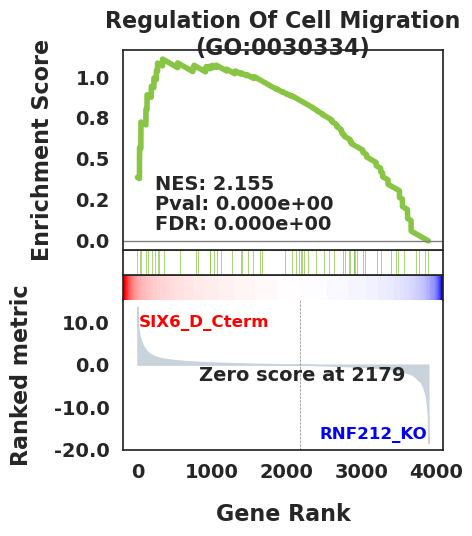

In [99]:
terms = res_BP.res2d.Term
axs = res_BP.plot(terms=terms[0]) # v1.0.5

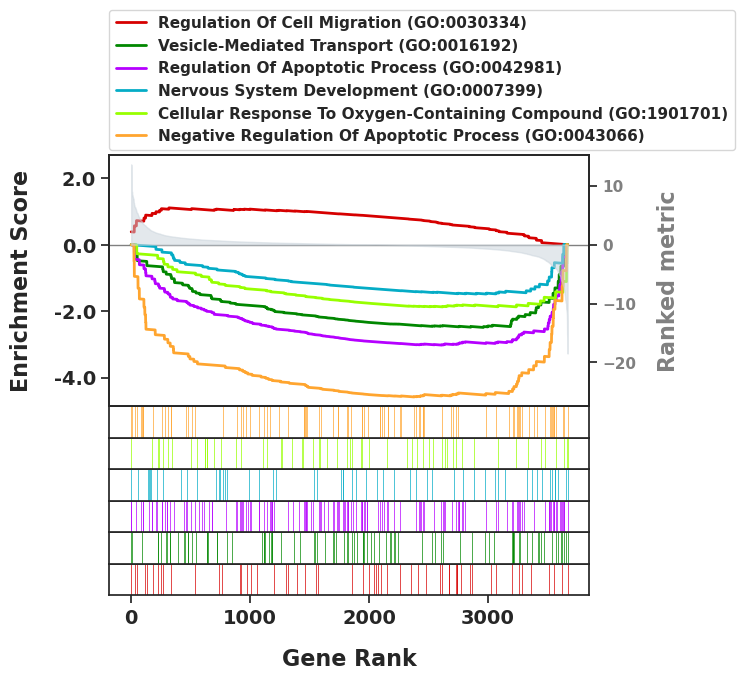

In [100]:
axs = res_BP.plot(terms=terms[:6])

In [101]:
res_MF = gp.gsea(data=pd.DataFrame(adata_subset.layers["normalized_expression_log"],columns=list(adata_subset.var_names.str.upper()),index=adata_subset.obs.index).T, # row -> genes, column-> samples
        gene_sets="GO_Molecular_Function_2023",
        cls=adata_subset.obs.Group,
        permutation_num=1000,
        min_size=40,
        permutation_type='phenotype',
        outdir=None,
        method='s2n', # signal_to_noise
        threads= 16)

In [102]:
res_MF.res2d.head(30)


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,gsea,Sequence-Specific DNA Binding (GO:0043565),-0.563797,-2.072329,0.0,0.0,0.0,18/83,14.13%,CHCHD2;HOXA4;CHTOP;UBA2;SIX1;ZBTB22;UPF3A;MAEL...
1,gsea,Transition Metal Ion Binding (GO:0046914),-0.414045,-1.759406,0.0,0.033296,0.032563,34/95,26.79%,FNTB;WDFY1;PHF1;FTH1;MSRB3;RNF125;NAPEPLD;MDM2...
2,gsea,Double-Stranded DNA Binding (GO:0003690),-0.444493,-1.697425,0.001984,0.048471,0.058824,26/78,30.03%,HOXA4;TOP1;UBA2;SIX1;ZBTB22;MSH3;ELF2;ZBTB32;P...
3,gsea,RNA Polymerase II Transcription Regulatory Reg...,-0.387204,-1.571045,0.006224,0.133523,0.159664,30/96,31.13%,HOXA4;TOP1;UBA2;SIX1;ZBTB22;TBPL1;HOXA3;MED8;E...
4,gsea,Zinc Ion Binding (GO:0008270),-0.426257,-1.551907,0.011858,0.126117,0.171218,20/70,18.97%,FNTB;WDFY1;PHF1;MSRB3;RNF125;NAPEPLD;MDM2;RNF2...
5,gsea,Cadherin Binding (GO:0045296),-0.366537,-1.470539,0.039337,0.210874,0.257353,43/91,39.64%,TLN1;CHMP2B;DNAJB1;SERBP1;RANBP1;EHD1;CCNB2;PC...
6,gsea,DNA-binding Transcription Factor Binding (GO:0...,-0.356032,-1.457681,0.037698,0.198998,0.27521,24/62,33.64%,CHCHD2;KEAP1;MAPK3;FIZ1;DUSP26;TBP;BBS10;METTL...
7,gsea,Tubulin Binding (GO:0015631),0.365443,1.455944,0.037773,0.655371,0.263,52/119,39.08%,KATNB1;GIT1;REEP2;SKA1;SBDS;TTLL13;ARL3;WHAMM;...
8,gsea,Sequence-Specific Double-Stranded DNA Binding ...,-0.403582,-1.447904,0.071713,0.186525,0.287815,32/82,36.00%,HOXA4;UBA2;SIX1;ZBTB22;CDK5RAP2;ELF2;ZBTB32;PR...
9,gsea,Cis-Regulatory Region Sequence-Specific DNA Bi...,-0.372479,-1.437417,0.035491,0.179541,0.296218,28/81,37.13%,HOXA4;TOP1;UBA2;SIX1;ZBTB22;HOXA3;MED8;PRKRA;R...


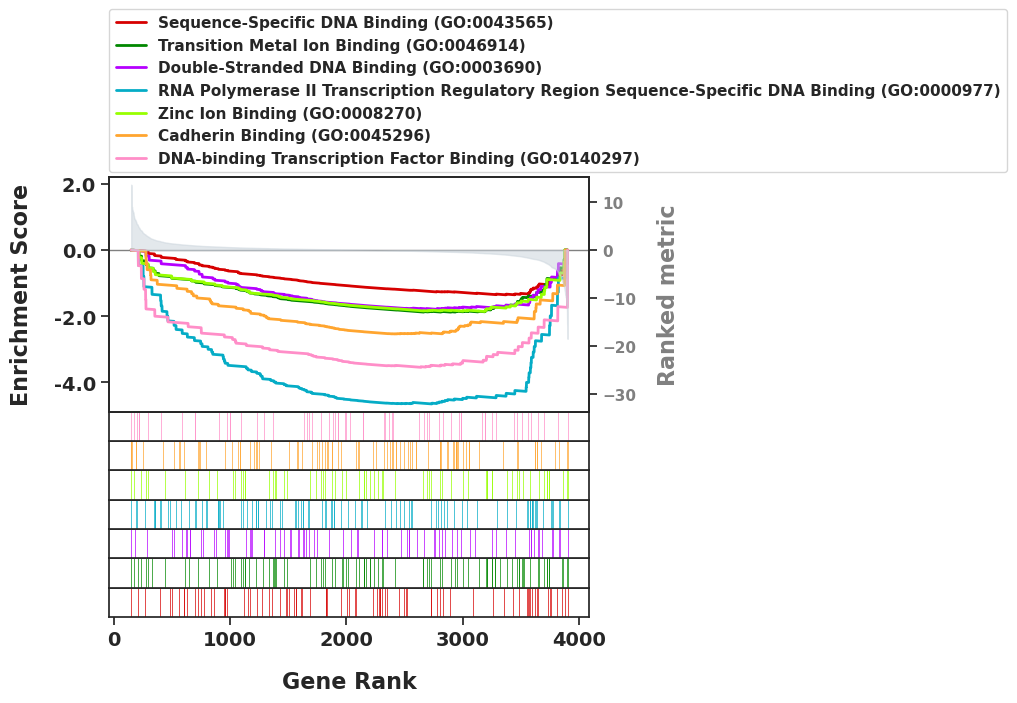

In [103]:
terms = res_MF.res2d.Term
axs = res_MF.plot(terms=terms[:7])

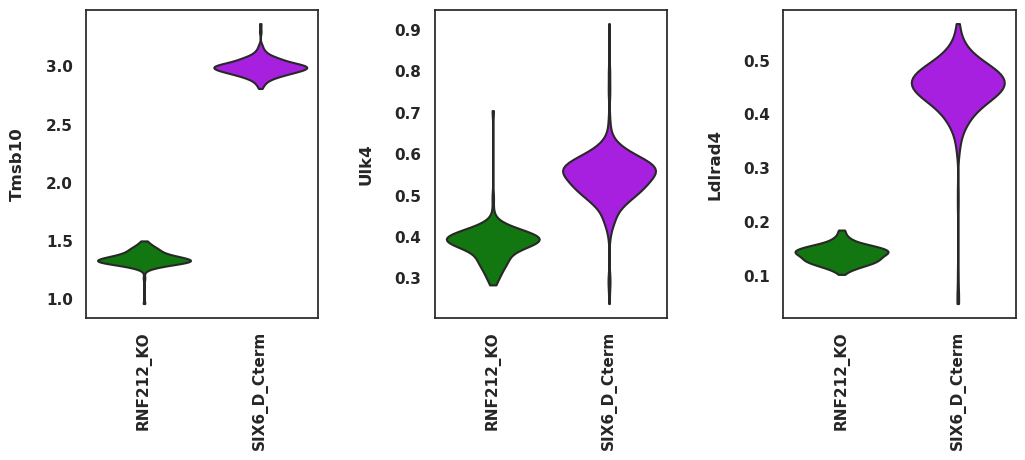

In [104]:
genes = ['Tmsb10', 'Ulk4',"Ldlrad4"]

# Create your own figure and axes: 1 row, 3 columns
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(genes),
    figsize=(12, 4),              # wider figure for horizontal layout
    constrained_layout=False,
    gridspec_kw={'wspace': 0.5}   # horizontal spacing between subplots
)

for ax, gene in zip(axes, genes):
    sc.pl.violin(
        subset,
        [gene],                 
        groupby='Group',
        jitter=0.4,
        rotation=90,
        stripplot=False,
        multi_panel=False,      
        show=False,
        ax=ax
    )

plt.show()


In [105]:
list_genes= pd.read_csv("/sas/sara/scRNAseq/pendas/tables/Selected_genes.txt",sep="\t")
list_genes

,Genes,Category
0,Spo11,DSB formation & end processing
1,Top6bl,DSB formation & end processing
2,Prdm9,DSB formation & end processing
3,Mei4,DSB formation & end processing
4,Rec114,DSB formation & end processing
...,...,...
146,Macroh2a1,Histones
147,Macroh2a2,Histones
148,H3f3a,Histones
149,H3f3b,Histones


In [106]:
len(set(list_genes["Genes"]) - set(adata.var_names))

107

In [107]:
de_sig = de_df[(de_df["pvals_adj"]<0.1) & (abs(de_df["logfoldchanges"]>0.5))]
de_sig

,names,scores,logfoldchanges,pvals,pvals_adj
0,Chchd2,251.356369,3.629580,5.083011e-204,1.211154e-200
1,Mpc2,224.719177,3.698056,2.588993e-166,1.121623e-163
2,Cox5a,205.081635,3.335495,8.276833e-168,3.944325e-165
3,Lsm4,195.202759,3.557496,1.518672e-147,2.783550e-145
4,Aknaos,175.256149,3.571823,5.417767e-132,5.612689e-130
...,...,...,...,...,...
3604,Slc40a1,2.120175,0.607573,3.592327e-02,4.740201e-02
3621,Snhg4,2.087050,0.604681,3.839666e-02,5.047008e-02
3644,Amer1,2.042664,0.796662,4.273279e-02,5.576208e-02
3681,Tab3,1.986357,0.561865,4.868446e-02,6.297660e-02


In [108]:
overlap = set(de_sig["names"]) & set(list_genes["Genes"])
overlap

{'Blm', 'Mnd1', 'Msh2', 'Spo11'}

In [109]:
list_genes[list_genes["Genes"].isin(overlap)]

,Genes,Category
0,Spo11,DSB formation & end processing
16,Mnd1,Strand invasion & HR machinery
28,Blm,Strand invasion & HR machinery
32,Msh2,Crossover designation & maturation


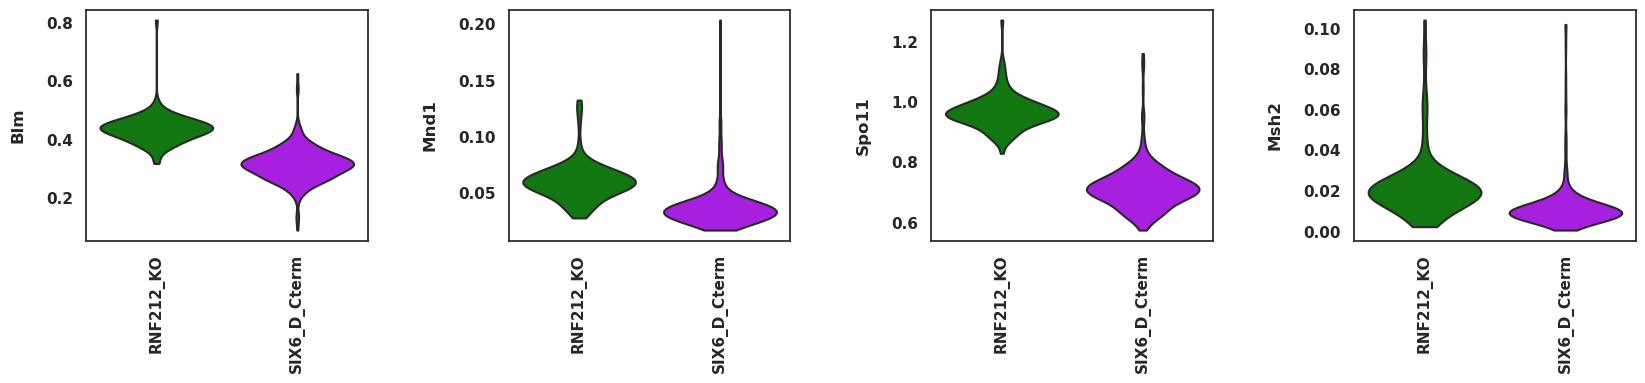

In [110]:

# Create your own figure and axes: 1 row, 3 columns
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(list(overlap)),
    figsize=(20, 3),              # wider figure for horizontal layout
    constrained_layout=False,
    gridspec_kw={'wspace': 0.5}   # horizontal spacing between subplots
)

for ax, gene in zip(axes, list(overlap)):
    sc.pl.violin(
        subset,
        [gene],                 
        groupby='Group',
        jitter=0.4,
        rotation=90,
        stripplot=False,
        multi_panel=False,      
        show=False,
        ax=ax
    )

plt.show()
